# The Quant Pipeline: From Fundamental Data to a Machine Learning-Based Long/Short Portfolio

## Part 1: Data Engineering and Preparation

### Research question

Can a machine learning model trained on company fundamentals identify stocks that outperform the S&P 500, and can those predictions later be translated into a long/short portfolio with meaningful risk-adjusted performance?

This first section prepares the raw `keystats.csv` data for exploratory analysis and later modeling. The main goals are to understand the structure of the data, handle observations that cannot be labeled, create the binary outperformance target, organize observations by calendar quarter, and inspect the predictor variables before the chronological train/test split.

### 1. Import libraries and load the dataset

The project uses Pandas and NumPy for data preparation and Matplotlib for visualizations. The column names are standardized to the format already used throughout this notebook.

In [1]:
# reading the file
import pandas as pd # Data manipulation and analysis
import numpy as np # numerical computing
import matplotlib.pyplot as plt # for visual purposes

df = pd.read_csv("keystats.csv")
df.columns = df.columns.str.capitalize()

df

/Users/souravchakraborty/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/souravchakraborty/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


,Date,Unix,Ticker,Price,Stock_p_change,Sp500,Sp500_p_change,Market cap,Enterprise value,Trailing p/e,...,200-day moving average,Avg vol (3 month),Shares outstanding,Float,% held by insiders,% held by institutions,Shares short (as of,Short ratio,Short % of float,Shares short (prior month)
0,2007-07-11,1184104768,ctas,33.538876,-33.02,122.084023,-15.90,6.350000e+09,7.080000e+09,19.13,...,39.30,1064470.0,158650000.0,135580000.0,17.81,64.70,4970000.0,4.200,3.70,4490000.0
1,2006-02-28,1141130339,ctas,34.026257,-0.79,100.297188,11.94,6.910000e+09,7.160000e+09,22.55,...,41.44,940276.0,168020000.0,140190000.0,16.59,66.20,3460000.0,3.400,2.50,4600000.0
2,2005-04-20,1113982724,ctas,31.885536,9.65,87.811470,17.27,6.750000e+09,7.020000e+09,23.35,...,43.13,1027318.0,172090000.0,122500000.0,28.82,65.87,6170000.0,6.479,5.04,6360000.0
3,2005-02-22,1109048563,ctas,35.317966,-4.10,91.157219,10.92,7.550000e+09,7.670000e+09,26.61,...,43.75,994136.0,171720000.0,122200000.0,28.84,63.20,5420000.0,4.740,4.44,4640000.0
4,2013-04-26,1366969360,ctas,41.474506,30.78,143.779022,20.10,5.480000e+09,6.550000e+09,18.46,...,42.70,580981.0,122520000.0,102370000.0,16.36,74.60,5060000.0,8.000,5.60,5860000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8677,2009-01-12,1231774186,vno,27.035572,41.34,72.243233,33.74,8.020000e+09,1.999000e+10,12.77,...,78.02,4530000.0,154350000.0,135220000.0,10.69,90.50,11070000.0,2.000,7.70,21800.0
8678,2009-09-18,1253239115,vno,37.499359,31.57,90.236214,7.49,1.214000e+10,2.328000e+10,NaN,...,46.64,3252510.0,178560000.0,163040000.0,9.83,93.70,13540000.0,4.900,8.10,14740000.0
8679,2012-11-05,1352070839,vno,48.554001,18.85,127.412491,26.98,1.504000e+10,5.550000e+09,26.99,...,82.61,988767.0,185810000.0,168560000.0,19.87,81.30,3010000.0,2.900,1.80,3150000.0
8680,2013-04-29,1367217482,vno,54.483345,21.23,144.742172,20.24,1.613000e+10,1.631000e+10,29.35,...,81.58,1027800.0,186730000.0,162270000.0,9.74,92.20,3280000.0,3.300,2.20,3460000.0


### 2. Initial structure of the dataset

The following cells inspect the number of observations and variables, the column names, data types, missing values, and descriptive statistics. This establishes what is available before any cleaning decisions are made.

In [2]:
print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Number of rows and columns: (8682, 48)

Column names:
['Date', 'Unix', 'Ticker', 'Price', 'Stock_p_change', 'Sp500', 'Sp500_p_change', 'Market cap', 'Enterprise value', 'Trailing p/e', 'Forward p/e', 'Peg ratio', 'Price/sales', 'Price/book', 'Enterprise value/revenue', 'Enterprise value/ebitda', 'Profit margin', 'Operating margin', 'Return on assets', 'Return on equity', 'Revenue', 'Revenue per share', 'Qtrly revenue growth', 'Gross profit', 'Ebitda', 'Net income avl to common', 'Diluted eps', 'Qtrly earnings growth', 'Total cash', 'Total cash per share', 'Total debt', 'Total debt/equity', 'Current ratio', 'Book value per share', 'Operating cash flow', 'Levered free cash flow', 'Beta', '50-day moving average', '200-day moving average', 'Avg vol (3 month)', 'Shares outstanding', 'Float', '% held by insiders', '% held by institutions', 'Shares short (as of', 'Short ratio', 'Short % of float', 'Shares short (prior month)']


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8682 entries, 0 to 8681
Data columns (total 48 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        8682 non-null   object 
 1   Unix                        8682 non-null   int64  
 2   Ticker                      8682 non-null   object 
 3   Price                       8578 non-null   float64
 4   Stock_p_change              8578 non-null   float64
 5   Sp500                       8682 non-null   float64
 6   Sp500_p_change              8682 non-null   float64
 7   Market cap                  8593 non-null   float64
 8   Enterprise value            8548 non-null   float64
 9   Trailing p/e                7887 non-null   float64
 10  Forward p/e                 8350 non-null   float64
 11  Peg ratio                   8215 non-null   float64
 12  Price/sales                 8565 non-null   float64
 13  Price/book                  8441 

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unix,8682.0,1.219222e+09,9.739501e+07,1.065084e+09,1.138921e+09,1.197831e+09,1.321592e+09,1.378419e+09
Price,8578.0,3.876936e+01,5.890436e+01,3.500000e-02,1.710935e+01,2.776132e+01,4.325834e+01,1.152803e+03
Stock_p_change,8578.0,1.765658e+01,4.559408e+01,-9.761000e+01,-4.427500e+00,1.323000e+01,3.299750e+01,6.483900e+02
Sp500,8682.0,1.067463e+02,1.996734e+01,5.658983e+01,9.105231e+01,1.086048e+02,1.196386e+02,1.546514e+02
Sp500_p_change,8682.0,9.832906e+00,1.613163e+01,-4.615000e+01,6.052500e+00,1.310000e+01,1.939750e+01,7.194000e+01
Market cap,8593.0,3.989195e+10,6.591613e+10,7.840000e+06,6.320000e+09,1.424000e+10,3.953000e+10,6.560000e+11
Enterprise value,8548.0,4.661039e+10,9.277280e+10,-5.130000e+11,7.250000e+09,1.636500e+10,4.727000e+10,8.990000e+11
Trailing p/e,7887.0,3.971043e+01,3.665257e+02,0.000000e+00,1.301500e+01,1.805000e+01,2.522500e+01,1.279500e+04
Forward p/e,8350.0,1.730121e+01,2.894064e+01,0.000000e+00,1.102250e+01,1.420000e+01,1.796750e+01,1.792000e+03
Peg ratio,8215.0,1.738963e+00,1.113180e+01,-3.425000e+02,1.010000e+00,1.350000e+00,1.830000e+00,6.850000e+02


In [5]:
# missing values in the raw dataset, sorting from highest to lowest missing values
print(df.isnull().sum().sort_values())

Date                             0
Unix                             0
Ticker                           0
Sp500                            0
Sp500_p_change                   0
Book value per share            66
Avg vol (3 month)               71
Net income avl to common        73
Revenue                         80
Shares outstanding              89
Market cap                      89
Shares short (as of             90
Shares short (prior month)      93
Short ratio                     94
Revenue per share               96
Diluted eps                    103
Price                          104
Stock_p_change                 104
50-day moving average          108
200-day moving average         115
Price/sales                    117
Total cash per share           125
Total debt                     126
Profit margin                  133
Enterprise value               134
Total cash                     136
Enterprise value/revenue       156
Operating margin               196
% held by institutio

The dataset contains stock identifiers, dates, market information, forward stock and S&P 500 percentage changes, and a broad set of company fundamentals. Several features contain missing values, with the largest gaps concentrated in quarterly growth and cash-flow variables. The forward stock return is also missing for a small number of observations, which must be handled before the target can be created.

### 3. Check duplicate records and repeated ticker-date combinations

A complete duplicate would indicate that the same row appears more than once. A repeated ticker-date combination is different: the same stock may appear more than once on the same date while some fundamental values differ. These records are inspected rather than automatically deleted.

In [6]:
print("Number of completely duplicated rows:", df.duplicated().sum())

duplicate_ticker_dates = df.duplicated(subset=["Ticker", "Date"], keep=False)
print("Number of rows involved in repeated ticker-date combinations:", duplicate_ticker_dates.sum())

df.loc[duplicate_ticker_dates, :].sort_values(["Ticker", "Date"]).head(20)

# select only the rows identified as duplicates by the
# duplicate_ticker_dates Boolean mask. The ':' indicates
# that all columns should be retained. The resulting rows
# are then sorted first by Ticker and then by Date so that
# duplicate observations appear next to one another,
# making them easier to inspect.

Number of completely duplicated rows: 0
Number of rows involved in repeated ticker-date combinations: 148


,Date,Unix,Ticker,Price,Stock_p_change,Sp500,Sp500_p_change,Market cap,Enterprise value,Trailing p/e,...,200-day moving average,Avg vol (3 month),Shares outstanding,Float,% held by insiders,% held by institutions,Shares short (as of,Short ratio,Short % of float,Shares short (prior month)
168,2011-09-24,1316794537,aapl,39.099064,78.50,99.845856,31.23,3.750000e+11,3.440000e+11,15.99,...,355.85,20920500.0,9.270900e+08,9.210500e+08,0.65,70.8,15160000.0,0.6,NaN,12540000.0
193,2011-09-24,1316814215,aapl,39.099064,78.50,99.845856,31.23,3.750000e+11,3.460000e+11,15.99,...,356.19,20884500.0,9.270900e+08,9.210500e+08,0.65,70.8,15160000.0,0.6,NaN,12540000.0
3823,2006-08-22,1156200245,acn,22.094664,45.07,102.631844,14.77,1.649000e+10,1.355000e+10,20.22,...,29.41,2239080.0,5.770600e+08,5.474000e+08,3.18,47.4,3080000.0,1.2,0.5,2730000.0
3832,2006-08-22,1156179041,acn,22.094664,45.07,102.631844,14.77,1.649000e+10,1.386000e+10,20.22,...,29.41,2239080.0,5.770600e+08,5.474000e+08,3.18,47.4,3080000.0,1.2,0.5,2730000.0
4783,2006-04-13,1144917267,amd,31.799999,-57.33,101.072968,14.99,1.570000e+10,1.661000e+10,82.63,...,31.27,17705600.0,4.808900e+08,3.675900e+08,0.12,78.9,17840000.0,1.1,3.7,17250000.0
4792,2006-04-13,1144867937,amd,31.799999,-57.33,101.072968,14.99,1.703000e+10,1.620000e+10,89.67,...,31.27,17705600.0,4.808900e+08,3.675900e+08,0.12,78.9,17840000.0,1.1,3.7,17250000.0
64,2006-04-12,1144788074,amzn,36.130001,16.99,101.206490,14.32,1.503000e+10,1.478000e+10,42.78,...,42.60,6453840.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0
107,2006-04-12,1144830231,amzn,36.130001,16.99,101.206490,14.32,1.514000e+10,1.478000e+10,43.08,...,42.60,6453840.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0
62,2006-04-27,1146070354,amzn,35.740002,75.15,102.894806,16.23,1.492000e+10,1.444000e+10,42.46,...,42.00,6385290.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0
104,2006-04-27,1146153315,amzn,35.740002,75.15,102.894806,16.23,1.490000e+10,1.444000e+10,42.40,...,42.00,6385290.0,4.169200e+08,3.105200e+08,25.38,66.6,35080000.0,5.7,11.2,34720000.0


The dataset does not contain completely duplicated rows, but some ticker-date combinations appear more than once. Because the repeated rows can contain slightly different fundamental values, they are retained at this stage instead of being treated as exact duplicates.

### 4. Convert dates, sort chronologically, and standardize tickers

Financial observations are time ordered/sensitive, so the date column is converted to a proper datetime type and the data are sorted from earliest to latest--order matters in financial observation. Ticker symbols are stripped of extra spaces and converted to uppercase so that formatting differences do not create artificial duplicates.

In [7]:
# Convert Date from text to a datetime variable
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Missing or invalid dates:", df["Date"].isna().sum())

# Standardize tickers and sort the dataset chronologically
df["Ticker"] = df["Ticker"].str.strip().str.upper()
df = df.sort_values(by=["Date", "Ticker"]).reset_index(drop=True)

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())
print("Number of unique stocks:", df["Ticker"].nunique())
# Count the number of distinct ticker symbols contained
# in the dataset. nunique() returns the number of unique
# values/stocks in the specified column.

df.head(20)

Missing or invalid dates: 0
Earliest date: 2003-10-02 00:00:00
Latest date: 2013-09-06 00:00:00
Number of unique stocks: 471


,Date,Unix,Ticker,Price,Stock_p_change,Sp500,Sp500_p_change,Market cap,Enterprise value,Trailing p/e,...,200-day moving average,Avg vol (3 month),Shares outstanding,Float,% held by insiders,% held by institutions,Shares short (as of,Short ratio,Short % of float,Shares short (prior month)
0,2003-10-02,1065085404,AMD,11.690000,14.88,76.901154,12.72,4.060000e+09,4.800000e+09,NaN,...,7.42,10463909.0,3.469600e+08,3.366000e+08,2.99,59.10,39840000.0,2.684,11.84,38840000.0
1,2003-10-02,1065083875,AMGN,57.050285,-12.68,76.901154,12.72,8.504000e+10,8.365000e+10,NaN,...,60.80,7888909.0,1.290000e+09,1.170000e+09,9.71,71.46,28000000.0,3.881,2.40,28230000.0
2,2003-10-02,1065087022,CVS,13.475180,35.60,76.901154,12.72,1.265000e+10,1.340000e+10,17.18,...,26.84,1932545.0,3.947100e+08,3.913000e+08,0.86,86.90,5140000.0,2.685,1.31,6230000.0
3,2003-10-02,1065087714,DIS,16.915346,11.27,76.901154,12.72,4.260000e+10,5.512000e+10,40.84,...,18.89,8466181.0,2.040000e+09,2.010000e+09,1.46,65.35,47860000.0,5.478,2.38,54720000.0
4,2003-10-02,1065088426,EBAY,11.595118,67.77,76.901154,12.72,3.511000e+10,3.341000e+10,112.78,...,46.39,12037181.0,6.420800e+08,4.946000e+08,22.97,64.41,34720000.0,2.904,7.02,36400000.0
5,2003-10-02,1065084099,MSFT,18.900982,-0.03,76.901154,12.72,3.060000e+11,2.590000e+11,31.00,...,25.87,54106318.0,1.082000e+10,9.200000e+09,14.97,53.12,123630000.0,2.234,1.34,108430000.0
6,2003-10-02,1065093642,NKE,3.410104,40.13,76.901154,12.72,1.639000e+10,1.629000e+10,21.04,...,51.38,1293818.0,2.637300e+08,1.311000e+08,50.29,55.17,7560000.0,7.787,5.77,6840000.0
7,2003-10-02,1065094861,NSC,13.572272,63.12,76.901154,12.72,7.360000e+09,1.478000e+10,15.43,...,19.64,1443818.0,3.902100e+08,3.369000e+08,13.66,68.26,2840000.0,1.861,0.84,3260000.0
8,2003-10-03,1065170920,ADSK,9.035097,175.89,77.606743,11.70,2.060000e+09,1.680000e+09,45.68,...,15.66,1072500.0,1.116000e+08,1.063000e+08,4.75,91.78,2220000.0,1.680,2.09,2220000.0
9,2003-10-03,1065173027,AES,6.781198,27.83,77.606743,11.70,4.930000e+09,2.367000e+10,NaN,...,5.43,2342272.0,6.197300e+08,5.352000e+08,13.64,69.94,8570000.0,4.499,1.60,9610000.0


The dataset spans approximately ten years and includes hundreds of unique stocks. Sorting the observations chronologically is important because the later modeling stage trains the Random Forest using historical information and evaluates it on future observations. Maintaining this time order helps preserve the natural sequence of the data and supports a realistic out-of-sample evaluation while avoiding look-ahead bias.

### 5. Remove observations without a usable target

The target variable is defined by comparing each stock's forward percentage change (Stock_p_change) with the corresponding forward percentage change of the S&P 500 (Sp500_p_change). If Stock_p_change is missing, the true target cannot be determined because the stock's future performance is unknown. Imputing a missing forward return would artificially create a target label that was never observed, introducing fabricated information into the dataset. Therefore, observations with missing Stock_p_change values are removed rather than imputed.

In [8]:
print("Missing target values before removal:")
print(df[["Stock_p_change", "Sp500_p_change"]].isnull().sum())

Original_df = df.copy()  # backup copy before dropping unusable target rows

df = df.dropna(subset=["Stock_p_change"]).reset_index(drop=True)

print("\nMissing target values after removal:")
print(df[["Stock_p_change", "Sp500_p_change"]].isnull().sum())

print("\nRows removed:", len(Original_df) - len(df))
print("Rows remaining:", len(df))

Missing target values before removal:
Stock_p_change    104
Sp500_p_change      0
dtype: int64

Missing target values after removal:
Stock_p_change    0
Sp500_p_change    0
dtype: int64

Rows removed: 104
Rows remaining: 8578


Only a small proportion of the observations is removed. This has a limited impact on the overall sample size and is preferable to assigning artificial future returns. Because the Random Forest is trained using supervised learning, each observation must have a valid and observed target label. Removing these rows therefore preserves the integrity of the training data.

### 6. Construct the binary outperformance target

The target variable is defined as:

- `1`: the stock's forward percentage change is greater than the S&P 500's forward percentage change.
- `0`: the stock does not outperform the S&P 500.

This converts the research question into a supervised binary classification problem.

In [9]:
# constructing the binary target variable
df["Outperform"] = np.where(df["Stock_p_change"] > df["Sp500_p_change"], 1, 0)

# np.where() evaluates the condition for every row in the DataFrame and
# assigns the corresponding class label.

# sanity check to see if outperform got created or not. 
df[["Ticker", "Date", "Stock_p_change", "Sp500_p_change", "Outperform"]].head(10)

,Ticker,Date,Stock_p_change,Sp500_p_change,Outperform
0,AMD,2003-10-02,14.88,12.72,1
1,AMGN,2003-10-02,-12.68,12.72,0
2,CVS,2003-10-02,35.60,12.72,1
3,DIS,2003-10-02,11.27,12.72,0
4,EBAY,2003-10-02,67.77,12.72,1
5,MSFT,2003-10-02,-0.03,12.72,0
6,NKE,2003-10-02,40.13,12.72,1
7,NSC,2003-10-02,63.12,12.72,1
8,ADSK,2003-10-03,175.89,11.70,1
9,AES,2003-10-03,27.83,11.70,1


### 7. Examine the class balance

A severely imbalanced target variable can cause a classification model to favor the majority class, leading to misleading performance metrics. The following analysis examines both the frequency and percentage of outperforming and non-outperforming observations to determine whether class imbalance is likely to influence model training.

Target counts:
Outperform
0    3950
1    4628
Name: count, dtype: int64

Target percentages:
Outperform
0    46.04803
1    53.95197
Name: proportion, dtype: float64


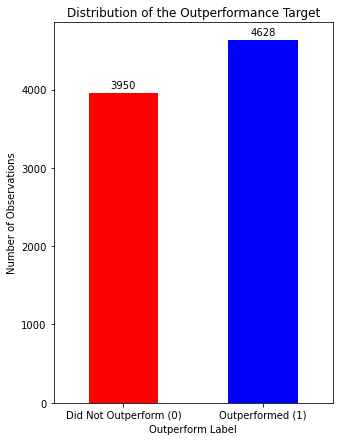

In [10]:
print("Target counts:")
print(df["Outperform"].value_counts().sort_index())
# count the number of observations belonging to each target
# class (0 = Did Not Outperform, 1 = Outperformed). This
# helps determine whether the dataset is balanced or if one
# class occurs much more frequently than the other.

print("\nTarget percentages:")
print(df["Outperform"].value_counts(normalize=True).sort_index().mul(100))
# calculate the percentage of observations belonging to each
# class. Setting normalize=True returns proportions instead
# of raw counts, while multiplying by 100 converts the
# proportions into percentages for easier interpretation.

target_counts = df["Outperform"].value_counts().sort_index()
# Store the class counts in a Series so they can be reused
# when creating the visualization below.

ax = target_counts.plot(kind="bar", figsize=(5, 7),color=["red", "blue"])

# Add the numbers on top of each bar
ax.bar_label(ax.containers[0], padding=3)

plt.title("Distribution of the Outperformance Target")
plt.xlabel("Outperform Label")
plt.ylabel("Number of Observations")
plt.xticks(ticks=[0, 1], labels=["Did Not Outperform (0)", "Outperformed (1)"], rotation=0)
plt.show()

The two target classes are reasonably balanced, although outperforming observations are slightly more common. As a result, severe class imbalance is unlikely to influence the Random Forest's training, making overall classification accuracy a more meaningful performance measure.

### 8. Create Calendar Quarters and Count Stocks per Quarter

Individual trading dates contain too few stocks to support meaningful stock ranking and portfolio formation. The observations are therefore grouped into calendar quarters, which provide a larger pool of stocks and will later serve as the portfolio construction periods.

Quarter
2003Q4    181
2004Q1     85
2004Q2    180
2004Q3    239
2004Q4    283
2005Q1    333
2005Q2    202
2005Q3     86
2005Q4     57
2006Q1    108
2006Q2    200
2006Q3    136
2006Q4    105
2007Q1    297
2007Q2    291
2007Q3     70
2007Q4    145
2008Q1    202
2008Q2    123
2008Q3     13
2008Q4    222
2009Q1    174
2009Q2     42
2009Q3     56
2009Q4     52
2010Q1     48
2010Q2     18
2010Q3     20
2010Q4     33
2011Q1     43
2011Q2    119
2011Q3    253
2011Q4    270
2012Q1    228
2012Q2    146
2012Q3    166
2012Q4    164
2013Q1    144
2013Q2    462
2013Q3     28
Freq: Q-DEC, Name: Ticker, dtype: int64

Smallest to Largest
 Quarter
2008Q3     13
2010Q2     18
2010Q3     20
2013Q3     28
2010Q4     33
2009Q2     42
2011Q1     43
2010Q1     48
2009Q4     52
2009Q3     56
2005Q4     57
2007Q3     70
2004Q1     85
2005Q3     86
2006Q4    105
2006Q1    108
2011Q2    119
2008Q2    123
2006Q3    136
2013Q1    144
2007Q4    145
2012Q2    146
2012Q4    164
2012Q3    166
2009Q1    174
2004Q2    18

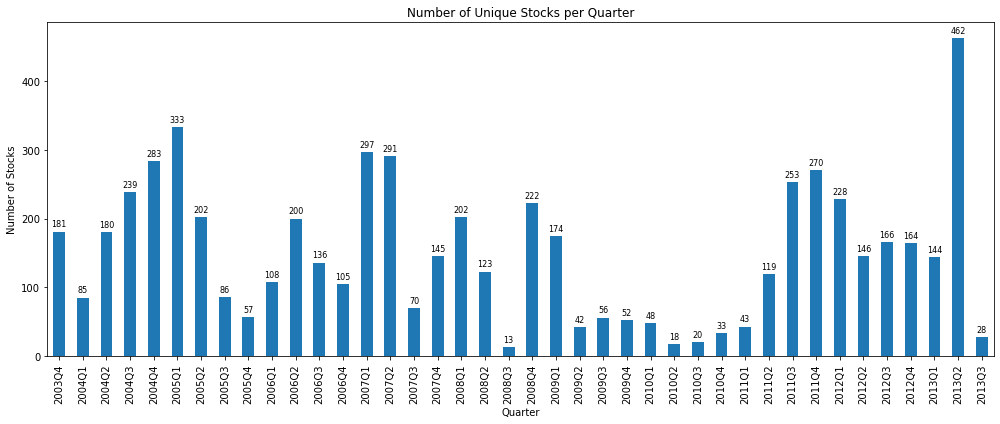

The Available Quarters: 40 Quarters


In [11]:
# create a quarterly time period from the date column.
# this will be used throughout the project to group stocks
# by calendar quarter.

df["Quarter"] = df["Date"].dt.to_period("Q")

# count the number of unique stocks available in each quarter.
# nunique() ensures that each ticker is only counted once,
# even if it appears multiple times within the same quarter.

stocks_per_quarter = df.groupby("Quarter")["Ticker"].nunique().sort_index()

print(stocks_per_quarter)
print("\nSmallest to Largest\n",stocks_per_quarter.sort_values())
print("\nQuarterly stock-count summary:\n")
print(stocks_per_quarter.describe())

ax = stocks_per_quarter.plot(kind="bar", figsize=(14, 6))
plt.title("Number of Unique Stocks per Quarter")
plt.xlabel("Quarter")
plt.ylabel("Number of Stocks")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
plt.tight_layout()
plt.show()

print(f"The Available Quarters: {stocks_per_quarter.count()} Quarters" )

The number of available stocks varies substantially across quarters. Most quarters contain a sufficiently large number of stocks for meaningful ranking, while a small number contain fewer than 30 stocks. Ranking very small groups may produce unstable portfolio selections and reduce the comparability of the long and short portfolios across quarters.

### 9. Exclude extremely thin quarters

A minimum threshold of 30 unique stocks per quarter is selected based on the observed distribution of quarterly stock counts. This threshold removes only the sparsest quarters while retaining periods with sufficient stock coverage for meaningful portfolio formation and subsequent analysis.

In [12]:
# Show the 10 quarters with the fewest unique stocks
print(stocks_per_quarter.sort_values().head(10), "\n")

MIN_STOCKS = 30

# identify all quarters that fall below the minimum stock
# threshold. these quarters will be removed from the dataset.
thin_quarters = stocks_per_quarter[stocks_per_quarter < MIN_STOCKS]
print("Quarters below the threshold, to be excluded:\n\n",thin_quarters )


valid_quarters = stocks_per_quarter[stocks_per_quarter >= MIN_STOCKS].index

# filter the dataset so that only observations belonging to
# the valid quarters remain. reset the index afterwards so
# the row numbers are sequential.
df = df[df["Quarter"].isin(valid_quarters)].reset_index(drop=True)

print("\nRemaining quarters:", df["Quarter"].nunique())
print("Remaining rows:", len(df))

# identify quarters that were retained but still contain
# relatively few stocks. these quarters are not removed,
# but are flagged for inspection.
remaining_counts = df.groupby("Quarter")["Ticker"].nunique().sort_index()
still_thin = remaining_counts[remaining_counts < 60]

print("\nRetained quarters that remain relatively thin:")
print(still_thin)

Quarter
2008Q3    13
2010Q2    18
2010Q3    20
2013Q3    28
2010Q4    33
2009Q2    42
2011Q1    43
2010Q1    48
2009Q4    52
2009Q3    56
Freq: Q-DEC, Name: Ticker, dtype: int64 

Quarters below the threshold, to be excluded:

 Quarter
2008Q3    13
2010Q2    18
2010Q3    20
2013Q3    28
Freq: Q-DEC, Name: Ticker, dtype: int64

Remaining quarters: 36
Remaining rows: 8485

Retained quarters that remain relatively thin:
Quarter
2005Q4    57
2009Q2    42
2009Q3    56
2009Q4    52
2010Q1    48
2010Q4    33
2011Q1    43
Freq: Q-DEC, Name: Ticker, dtype: int64


Four quarters fall below the 30-stock requirement and are excluded. Several retained quarters remain smaller than the typical quarter, so their eventual portfolio results should be interpreted cautiously because each selected stock will carry greater influence.

### 10. Review features (independent variables) with substantial missing data

Several fundamental variables contain noticeably more missing values than the rest of the dataset, particularly the quarterly growth and cash flow measures. These variables are reviewed to assess whether they retain enough information for meaningful analysis. Although each feature contains a relatively large number of missing values, each also retains several thousand valid observations. Therefore, they are not removed at this stage. Missing values will instead be addressed after the chronological train-test split using statistics calculated from the training data only, preventing information from the testing period from leaking into the training process.

In [13]:
df.isnull().sum().sort_values().tail(5)

Total debt/equity         1409
Qtrly revenue growth      2077
Operating cash flow       2723
Qtrly earnings growth     2882
Levered free cash flow    3127
dtype: int64

### 11. Check for infinite numerical values

Financial ratios can become infinite when a denominator is zero or extremely close to zero. Because machine learning models require finite numerical inputs, the numerical variables are checked for infinite values before model development.

In [14]:
numeric_columns = df.select_dtypes(include=np.number).columns
# check only the numeric columns since infinite values can
# only exist in numerical data.

infinite_counts = pd.Series({column: np.isinf(df[column]).sum() for column in numeric_columns})
# count the number of positive and negative infinite values
# in each numeric column. np.isinf() returns True wherever
# an infinite value is found, and sum() counts how many
# occur in each column.

print("Columns containing infinite values:")
print(infinite_counts[infinite_counts > 0].sort_values(ascending=False))

Columns containing infinite values:
Series([], dtype: int64)


No infinite values were detected in the numerical features. This indicates that the financial ratios are already represented as finite values, so no replacement or removal of infinite observations is required before model development.

### 12. Focused descriptive statistics and boxplots

A selected group of familiar financial variables is selected to illustrate differences in scale and distribution without overwhelming the reader by displaying every feature. The y-axis is restricted to improve the readability of the central portion of each boxplot. This visualization is used for exploratory analysis only; extreme observations are not removed or modified at this stage.

In [15]:
selected_features = [
    "Trailing p/e",
    "Forward p/e",
    "Peg ratio",
    "Profit margin",
    "Return on equity",
    "Total debt/equity",
    "Beta",
    "Short ratio"]

df[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Trailing p/e,7744.0,39.964560,369.857711,0.000,13.0375,18.0650,25.2725,12795.00
Forward p/e,8186.0,17.339659,29.181493,0.000,11.0500,14.2100,17.9800,1792.00
Peg ratio,8060.0,1.738577,11.235281,-342.500,1.0100,1.3500,1.8300,685.00
Profit margin,8365.0,10.789378,17.883422,-282.140,4.8600,9.4000,16.8200,157.14
Return on equity,8199.0,25.527879,152.340997,-1642.390,9.6200,16.5800,24.2600,3544.63
Total debt/equity,7076.0,41.924157,259.077969,-13.342,0.3460,1.0360,32.4475,16174.36
Beta,7992.0,1.183227,0.813001,-2.530,0.6200,1.0685,1.5900,6.35
Short ratio,8406.0,3.557015,2.915274,0.000,1.8000,2.7000,4.3420,31.60


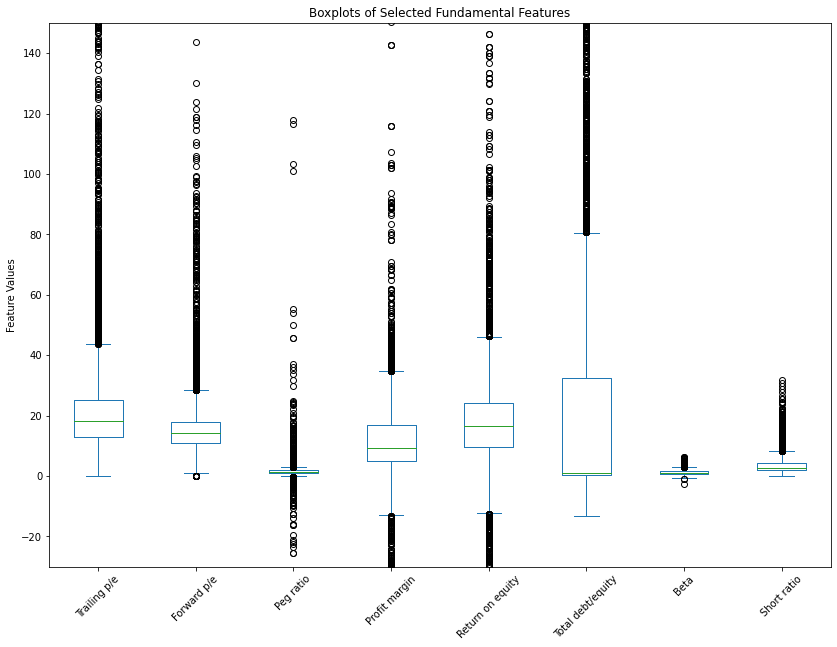

In [16]:
df[selected_features].plot(kind="box", figsize=(14, 10), rot=45)
plt.ylim(-30, 150)
plt.title("Boxplots of Selected Fundamental Features")
plt.ylabel("Feature Values")
plt.show()

The selected financial variables operate on very different scales, and several exhibit substantial variability and long-tailed distributions. For example, variables such as Trailing P/E, Return on Equity, and Total Debt/Equity contain extremely large maximum values relative to their medians, indicating the presence of outliers. Such behavior is common in financial statement data and valuation ratios. Random Forests do not require feature standardization in the same way as distance-based or linear models, although extreme observations may still influence individual tree splits. These characteristics are examined during exploratory analysis, but no outlier treatment is performed before the chronological train-test split.

### 13. Define the candidate model features and inspect correlation

Date and ticker identifiers, the stock's raw price level, market benchmark variables, forward-return outcomes, the target variable, and the quarter identifier are excluded from the Random Forest because they do not represent independent predictive information. Raw price is excluded because its absolute level differs by stock and does not reflect a company's underlying fundamentals the way the other predictors do. The two forward percentage-change variables are excluded because using them would create direct target leakage, since the target itself is derived from them.

The remaining predictor variables are then examined for linear relationships using a correlation analysis. This step is performed for diagnostic purposes only to identify highly correlated financial features and better understand the structure of the dataset. Because the dataset contains a large number of predictor variables, a full correlation heatmap would produce a crowded visualization that is difficult to interpret. Instead, only feature pairs with an absolute correlation greater than or equal to 0.80 are reported, providing a clearer summary of the strongest relationships.

No correlated predictors are removed at this stage. Although Random Forests are generally less sensitive to multicollinearity than many linear models, the correlation analysis helps identify potentially redundant features. Any decision to remove or combine correlated variables would be made after the chronological train-test split using the training data only, ensuring that no information from the testing period influences model development.

In [17]:
exclude_columns = ["Date", "Unix", "Ticker", "Price", 
                   "Stock_p_change", "Sp500", "Sp500_p_change", 
                   "Quarter", "Outperform"]

feature_columns = [column for column in df.columns if column not in exclude_columns]

print("Number of candidate fundamental features:", len(feature_columns))
print("\n", feature_columns)

Number of candidate fundamental features: 41

 ['Market cap', 'Enterprise value', 'Trailing p/e', 'Forward p/e', 'Peg ratio', 'Price/sales', 'Price/book', 'Enterprise value/revenue', 'Enterprise value/ebitda', 'Profit margin', 'Operating margin', 'Return on assets', 'Return on equity', 'Revenue', 'Revenue per share', 'Qtrly revenue growth', 'Gross profit', 'Ebitda', 'Net income avl to common', 'Diluted eps', 'Qtrly earnings growth', 'Total cash', 'Total cash per share', 'Total debt', 'Total debt/equity', 'Current ratio', 'Book value per share', 'Operating cash flow', 'Levered free cash flow', 'Beta', '50-day moving average', '200-day moving average', 'Avg vol (3 month)', 'Shares outstanding', 'Float', '% held by insiders', '% held by institutions', 'Shares short (as of', 'Short ratio', 'Short % of float', 'Shares short (prior month)']


In [18]:
correlation_matrix = df[feature_columns].corr()

# store feature pairs whose absolute correlation exceeds
# the chosen threshold.
high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i,j]) >=0.8:
            high_corr_pairs.append([correlation_matrix.columns[i], 
                                    correlation_matrix.columns[j],correlation_matrix.iloc[i,j]])

high_corr_pairs_df = pd.DataFrame(
    high_corr_pairs, 
    columns = ["Feature 1", "Feature 2", "Correlation"]).sort_values("Correlation", key = abs)     
            
print(f"Number of feature pairs with |correlation| >= 0.80: {len(high_corr_pairs_df)} pairs")
high_corr_pairs_df.head(20)
        

Number of feature pairs with |correlation| >= 0.80: 21 pairs


,Feature 1,Feature 2,Correlation
3,Gross profit,Revenue,0.800820
2,Gross profit,Market cap,0.811399
5,Ebitda,Enterprise value,0.817186
0,Enterprise value,Market cap,0.831348
6,Ebitda,Revenue,0.836625
8,Net income avl to common,Market cap,0.846393
13,Total debt,Total cash,0.854689
4,Ebitda,Market cap,0.876453
14,Book value per share,Revenue per share,0.910809
7,Ebitda,Gross profit,0.911788


Several financial variables exhibit strong linear relationships because they measure similar aspects of company valuation, profitability, leverage, cash flow, or ownership. Such relationships are common in fundamental financial data. Although Random Forests are generally more tolerant of correlated predictors than many linear models, highly correlated variables can distribute feature importance across similar predictors, making individual importance scores more difficult to interpret. Therefore, all features are retained at this stage, and their relative importance will be evaluated after the Random Forest has been trained.

## Part 1 Conclusion

The raw dataset has now been transformed into a structure suitable for chronological machine learning model development. Specifically:

- Dates and ticker symbols have been standardized.
- Observations without valid forward stock returns have been removed.
- A binary target variable identifying stock outperformance has been created.
- Observations have been grouped into calendar quarters.
- Quarters containing fewer than 30 unique stocks have been excluded.
- Features with substantial missingness have been retained for later imputation using the training data only.
- Numerical variables have been checked for infinite values, and selected feature distributions have been examined through descriptive statistics and boxplots.
- Candidate predictor variables have been separated from identifiers, target variables, and future outcome information to prevent data leakage.
- Correlations among the predictor variables have been examined without making premature feature-selection decisions.

- Overall, the dataset has been cleaned, organized, and prepared for chronological machine learning analysis while minimizing the risk of data leakage.

### Next Step: Train-Test Split

The next stage chronologically divides the dataset into training and testing periods. After the split, missing predictor values will be imputed using statistics calculated from the training data only, ensuring that no information from the testing period influences model development.

# Part 2: Chronological Train-Test Split

A random split would mix earlier and later market observations. That would not reflect how the model would be used in practice, because a real investment model must learn from historical information before making predictions about later periods.

After filtering the very thin quarters, 36 usable quarters remain. The most recent 10 available quarters are reserved for out-of-sample testing, while the preceding 26 quarters are used for training. This provides a substantial training history while retaining enough quarterly test periods for the later portfolio-performance and risk analysis.

### 14. Identify the available quarters

The quarters are sorted chronologically so that the cutoff can be selected from the actual periods remaining after the earlier filtering step.

In [19]:
# get all unique calendar quarters and sort them
# chronologically. this creates the ordered timeline that
# will be used to split the data into training and testing
# periods.
quarters = sorted(df["Quarter"].unique())

print(quarters)
print("\nNumber of available quarters:", len(quarters))

[Period('2003Q4', 'Q-DEC'), Period('2004Q1', 'Q-DEC'), Period('2004Q2', 'Q-DEC'), Period('2004Q3', 'Q-DEC'), Period('2004Q4', 'Q-DEC'), Period('2005Q1', 'Q-DEC'), Period('2005Q2', 'Q-DEC'), Period('2005Q3', 'Q-DEC'), Period('2005Q4', 'Q-DEC'), Period('2006Q1', 'Q-DEC'), Period('2006Q2', 'Q-DEC'), Period('2006Q3', 'Q-DEC'), Period('2006Q4', 'Q-DEC'), Period('2007Q1', 'Q-DEC'), Period('2007Q2', 'Q-DEC'), Period('2007Q3', 'Q-DEC'), Period('2007Q4', 'Q-DEC'), Period('2008Q1', 'Q-DEC'), Period('2008Q2', 'Q-DEC'), Period('2008Q4', 'Q-DEC'), Period('2009Q1', 'Q-DEC'), Period('2009Q2', 'Q-DEC'), Period('2009Q3', 'Q-DEC'), Period('2009Q4', 'Q-DEC'), Period('2010Q1', 'Q-DEC'), Period('2010Q4', 'Q-DEC'), Period('2011Q1', 'Q-DEC'), Period('2011Q2', 'Q-DEC'), Period('2011Q3', 'Q-DEC'), Period('2011Q4', 'Q-DEC'), Period('2012Q1', 'Q-DEC'), Period('2012Q2', 'Q-DEC'), Period('2012Q3', 'Q-DEC'), Period('2012Q4', 'Q-DEC'), Period('2013Q1', 'Q-DEC'), Period('2013Q2', 'Q-DEC')]

Number of available quarte

The cleaned dataset contains 36 usable quarters. Some calendar quarters are absent because they contained fewer than 30 stocks and were removed during Part 1.

### 15. Reserve the Most Recent 10 Quarters for Testing

The most recent **10 calendar quarters** are reserved for out-of-sample testing, while all earlier quarters are used for model training. The first of these 10 quarters serves as the chronological cutoff between the training and testing periods. This approach ensures that the Random Forest is trained exclusively on historical observations before being evaluated on later, previously unseen data, closely reflecting how an investment model would operate in practice.

In [20]:
# use the most recent 10 quarters as the out-of-sample
# testing period. everything before this quarter will be
# used for training.
test_start = quarters[-10]

# split the dataset chronologically. using a time based
# split prevents future information from leaking into the
# training data.

train_df = df[df["Quarter"] < test_start]
test_df = df[df["Quarter"] >= test_start]

# verify that the split produced the expected number of
# training and testing quarters.

print("Testing period starts:", test_start)
print("\nTraining quarters:", train_df["Quarter"].nunique())
print("Testing quarters:", test_df["Quarter"].nunique())

print("\nTraining period:", train_df["Quarter"].min(), "to", train_df["Quarter"].max())
print("Testing period:", test_df["Quarter"].min(), "to", test_df["Quarter"].max())

print("\nTraining observations:", len(train_df))
print("Testing observations:", len(test_df))

Testing period starts: 2011Q1

Training quarters: 26
Testing quarters: 10

Training period: 2003Q4 to 2010Q4
Testing period: 2011Q1 to 2013Q2

Training observations: 5550
Testing observations: 2935


The training period consists of 26 calendar quarters, spanning 2003Q4 through 2010Q4, while the testing period consists of the 10 most recent quarters, spanning 2011Q1 through 2013Q2. The testing observations remain completely separate from the training data and are not used to estimate the Random Forest or calculate any preprocessing statistics. This separation ensures that the model is evaluated on previously unseen data, providing a realistic assessment of its out-of-sample performance.

# Part 3: Training-Set Preprocessing

The predictor variables and target variable are now separated in preparation for model development. Any preprocessing step that learns information from the data must be performed using the training set only. This is particularly important for missing-value imputation because calculating summary statistics from the full dataset would allow information from the testing period to influence model development, introducing data leakage.

### 16. Separate the Predictors from the Target

`X_train` and `X_test` contain the **41 candidate predictor variables** used to train and evaluate the Random Forest. `y_train` and `y_test` contain the binary **Outperform** target variable, indicating whether a stock outperformed the S&P 500 over the forward return period.

In [21]:
# separate the predictor variables (X) from the target
# variable (y) for both the training and testing datasets.
# X contains the input features used by the model, while
# y contains the binary labels the model is trying to
# predict.

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df["Outperform"]
y_test = test_df["Outperform"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5550, 41)
X_test shape: (2935, 41)

y_train shape: (5550,)
y_test shape: (2935,)


The predictor and target dimensions agree within each period: every training row has one training label, and every testing row has one testing label. The same 41 feature columns are present in both predictor sets.

### 17. Examine Missingness in the Training Predictors

Missing values are examined using **`X_train` only**, because the training data represent the information available when the model is developed. Evaluating missingness at this stage identifies which predictor variables require imputation while ensuring that no information from the testing period influences the preprocessing decisions.

In [22]:
# count the number of missing values in each training
# feature and sort the results from the highest count to
# the lowest.

train_missing = X_train.isnull().sum().sort_values(ascending=False)
train_missing_percent = X_train.isnull().mean().sort_values(ascending=False).mul(100)

print("Training features with missing values:")
print(train_missing[train_missing > 0])

print("\nTraining feature missing percentages:")
print(train_missing_percent[train_missing_percent > 0])

Training features with missing values:
Levered free cash flow        2638
Qtrly earnings growth         2432
Operating cash flow           2423
Qtrly revenue growth          2014
Total debt/equity              965
Current ratio                  695
Enterprise value/ebitda        669
Ebitda                         543
Trailing p/e                   505
Beta                           412
Peg ratio                      364
Float                          287
Forward p/e                    201
Return on assets               178
Return on equity               175
Operating margin               175
Price/book                     152
Enterprise value/revenue       135
Short % of float               133
% held by insiders             123
Enterprise value               113
Profit margin                  111
Gross profit                    98
Total debt                      95
% held by institutions          95
200-day moving average          95
Price/sales                     93
Total cash      

The quarterly growth and cash flow variables exhibit the highest levels of missingness within the training data. Several of these features are missing for more than 40% of the training observations. Nevertheless, they are retained because each still contains thousands of observed values and may provide useful financial information to the model. Missing values will be imputed using the training-set median, preserving these variables for analysis. However, median imputation cannot recover the company-specific information contained in the missing observations, making this an important limitation that will be discussed later.

### 18. Impute Missing Values with Training-Set Medians

The median is used to impute missing values because many financial variables exhibit skewed distributions and contain extreme observations. Compared with the mean, the median is less influenced by unusually large or small values, making it a more robust choice for financial data.

The imputation values are calculated using **`X_train` only**. These same training-set medians are then applied to both **`X_train`** and **`X_test`**, ensuring that no information from the testing period influences the preprocessing stage and preventing data leakage.

In [23]:
# calculate the median of each feature using only the
# training dataset. each feature receives its own median
# value, which will be used to fill missing observations.

train_medians = X_train.median()

# replace missing values in both the training and testing
# datasets using the medians calculated from the training
# data. the same values must be used for both datasets to
# ensure the testing data remains completely unseen during
# model training.

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# Confirm that the model inputs no longer contain missing values
print("Total missing values in X_train:", X_train.isnull().sum().sum())
print("Total missing values in X_test:", X_test.isnull().sum().sum())

Total missing values in X_train: 0
Total missing values in X_test: 0


Both predictor sets now contain zero missing values and can be passed to the Random Forest. The variables are not standardized because decision-tree models split features at numerical thresholds and do not require all predictors to share the same scale.

### 19. Verify Class Balance Across the Training and Testing Periods

The proportion of outperforming and non-outperforming observations is examined separately in the training and testing datasets. Any differences between the two periods may reflect changes in underlying market conditions rather than errors introduced during preprocessing. Verifying the class balance also helps determine whether the model is being evaluated under conditions similar to those observed during training.

In [24]:
# Compare the percentage of each target class across the two time periods
print("Training target percentages:")
print(y_train.value_counts(normalize=True).sort_index().mul(100))

print("\nTesting target percentages:")
print(y_test.value_counts(normalize=True).sort_index().mul(100))

Training target percentages:
Outperform
0    43.765766
1    56.234234
Name: proportion, dtype: float64

Testing target percentages:
Outperform
0    49.914821
1    50.085179
Name: proportion, dtype: float64


The training period contains a somewhat larger share of outperforming observations, while the testing period is almost evenly divided between the two classes. This difference reinforces the need to evaluate the model on later observations rather than relying only on its training performance.

### 20. Final preprocessing verification

The final check summarizes the number of predictors and observations and confirms that no missing values remain before model training.

In [25]:
# Final verification before fitting the Random Forest
print("Number of model features:", X_train.shape[1])
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("\nTotal missing values in training data:", X_train.isnull().sum().sum())
print("Total missing values in testing data:", X_test.isnull().sum().sum())

Number of model features: 41
Training observations: 5550
Testing observations: 2935

Total missing values in training data: 0
Total missing values in testing data: 0


## Parts 2 and 3 conclusion

The data have now been divided chronologically into an earlier training period and a later out-of-sample testing period. The predictors and target have been separated, and all missing predictor values have been filled using medians calculated only from the training data.

We are now ready for the modeling stage:

- `X_train` and `y_train` for fitting the Random Forest;
- `X_test` and `y_test` for out-of-sample evaluation;

Part 4 will train a baseline Random Forest classifier, compare its training and testing performance, generate outperformance probabilities, and examine feature importance.

# Part 4: Random Forest Classification

The prepared training data are now used to build a baseline Random Forest classifier. The purpose of this section is not only to generate binary predictions, but also to estimate the probability that each stock will outperform the S&P 500 over the forward return period. These predicted probabilities will later be used to rank stocks within each calendar quarter and construct the long and short portfolios.

A baseline model is used to establish an initial measure of predictive performance. The classifier contains **100 decision trees**, and `random_state = 42` is specified to ensure that the results are reproducible.

### 21. Train the baseline Random Forest

The model learns the relationship between the 41 candidate features and the binary `Outperform` target using only the chronological training period. Predictions are then generated for both the training and testing sets so that in-sample and out-of-sample performance can be compared.

In [26]:
# Import the Random Forest model and classification metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# create the random forest model. n_estimators specifies
# the number of decision trees to build, while random_state
# ensures the results are reproducible each time the code
# is run.

random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest.fit(X_train, y_train)

# Generate class predictions for the training and testing periods
y_train_predictions = random_forest.predict(X_train)
y_test_predictions = random_forest.predict(X_test)

# calculate the baseline accuracy obtained by always
# predicting the majority class in the testing dataset.
# the trained model should outperform this simple benchmark.

train_accuracy = accuracy_score(y_train, y_train_predictions)
test_accuracy = accuracy_score(y_test, y_test_predictions)
baseline_accuracy = y_test.value_counts(normalize=True).max()

print("Training Accuracy:", train_accuracy * 100)
print("Testing Accuracy:", test_accuracy * 100)
print("Baseline Accuracy:", baseline_accuracy * 100)

Training Accuracy: 99.56756756756758
Testing Accuracy: 49.13117546848382
Baseline Accuracy: 50.08517887563884


The model achieves nearly perfect training accuracy but only **49.13%** testing accuracy, which is slightly below the **50.09%** majority-class baseline. The large gap between the training and testing accuracies indicates substantial overfitting: the decision trees learn the training observations extremely well but do not generalize effectively to later market periods.

Although the baseline classifier performs poorly as a binary classifier, this does not necessarily prevent it from producing useful probability estimates. The primary objective of this project is not simply to classify stocks as outperformers or non-outperformers, but to rank them according to their predicted probabilities. The following sections therefore examine whether these probability estimates still provide a meaningful relative ranking for constructing the long and short portfolios.

### 22. Evaluate the testing predictions

Accuracy alone does not show how the model performs on each class. Precision, recall, the F1 score, the classification report, and the confusion matrix provide a more complete view of the testing results.

Accuracy: 0.4913117546848382
Precision: 0.49382716049382713
Recall: 0.6258503401360545
F1 Score: 0.552055205520552

Classification report:
              precision    recall  f1-score   support

           0       0.49      0.36      0.41      1465
           1       0.49      0.63      0.55      1470

    accuracy                           0.49      2935
   macro avg       0.49      0.49      0.48      2935
weighted avg       0.49      0.49      0.48      2935

Confusion matrix:

 [[522 943]
 [550 920]]


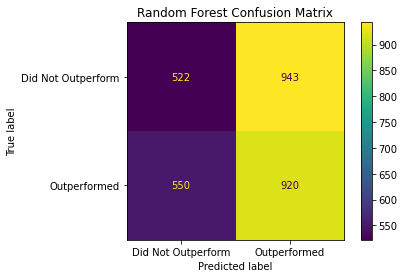

In [27]:
# Calculate the main out-of-sample classification metrics
print("Accuracy:", accuracy_score(y_test, y_test_predictions))
print("Precision:", precision_score(y_test, y_test_predictions))
print("Recall:", recall_score(y_test, y_test_predictions))
print("F1 Score:", f1_score(y_test, y_test_predictions))

print("\nClassification report:")
print(classification_report(y_test, y_test_predictions))

# calculate the confusion matrix, which summarizes the
# number of true positives, true negatives, false
# positives, and false negatives made by the model.

confusion_matrix_results = confusion_matrix(y_test, y_test_predictions)
print("Confusion matrix:\n\n", confusion_matrix_results)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_results,
    display_labels=["Did Not Outperform", "Outperformed"]).plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

The Random Forest achieves a higher recall for the outperforming class (0.63) than for the non-outperforming class (0.36). In other words, the model correctly identifies a larger proportion of the stocks that ultimately outperform the S&P 500, but it also misclassifies many non-outperforming stocks as outperformers. This behavior is reflected in the testing precision of approximately 49%, indicating that fewer than half of the stocks predicted to outperform actually do so over the forward return period.

The confusion matrix provides the same conclusion. Of the 1,470 stocks that actually outperformed, the model correctly identifies 920 but misses 550. Conversely, of the 1,465 stocks that did not outperform, only 522 are correctly classified, while 943 are incorrectly predicted to outperform. As a result, the Random Forest favors predicting the outperformance class, producing a large number of false-positive predictions.

These findings are consistent with the weak out-of-sample accuracy (49.13%) and indicate that the baseline Random Forest is not a strong binary classifier. However, the objective of this project is to rank stocks by their predicted probabilities rather than rely solely on binary class labels. The following section therefore evaluates whether these predicted probabilities still provide a meaningful ranking for constructing the long and short portfolios.

### 23. Generate Outperformance Probabilities

The Random Forest's `predict_proba()` method estimates the probability that each stock belongs to each of the two classes. Column **0** contains the estimated probability that a stock **does not outperform** the S&P 500, while column **1** contains the estimated probability that it **outperforms** the S&P 500 over the forward return period.

Only the class 1 probabilities are retained because they provide a continuous measure of the model's confidence that a stock will outperform. 

In [28]:
# generate the predicted probability that each stock in the
# testing period will outperform the S&P 500. predict_proba()
# returns probabilities for both classes, and [:, 1] selects
# only the probability of the positive class (Outperform = 1).

test_probabilities = random_forest.predict_proba(X_test)[:, 1]

print(test_probabilities[:20])

# Reconnect the model outputs to the stock and realized-return information
test_results = test_df[
    ["Date", "Quarter", "Ticker", "Stock_p_change", "Sp500_p_change", "Outperform"]
].copy()

test_results["Predicted_class"] = y_test_predictions
test_results["Outperform_probability"] = test_probabilities

test_results.sort_values("Outperform_probability").head(20)

[0.53 0.94 0.67 0.44 0.49 0.63 0.44 0.4  0.94 0.58 0.57 0.66 0.91 0.48
 0.39 0.65 0.6  0.5  0.57 0.89]


,Date,Quarter,Ticker,Stock_p_change,Sp500_p_change,Outperform,Predicted_class,Outperform_probability
5665,2011-04-29,2011Q2,JPM,-2.26,5.07,0,0,0.10
6242,2011-11-04,2011Q4,JPM,28.60,15.23,1,0,0.17
5966,2011-09-03,2011Q3,JPM,10.60,22.32,0,0,0.18
5875,2011-08-17,2011Q3,BK,10.95,21.17,0,0,0.25
6562,2012-01-03,2012Q1,JPM,32.38,17.10,1,0,0.25
6889,2012-03-09,2012Q1,JPM,25.95,15.50,1,0,0.25
5769,2011-07-02,2011Q3,TDC,18.22,3.79,1,0,0.26
6803,2012-02-26,2012Q1,DO,7.91,11.23,0,0,0.26
5771,2011-07-03,2011Q3,TDC,18.01,4.10,1,0,0.26
5857,2011-08-14,2011Q3,TSLA,18.47,21.71,0,0,0.27


### 23b. Examine the Distribution of Predicted Probabilities

A histogram of the predicted outperformance probabilities illustrates how confident the Random Forest is across the testing dataset. Specifically, it shows whether the predicted probabilities cluster around **0.50**, indicating little confidence in either class, or extend toward **0** and **1**, indicating stronger confidence in the model's predictions. Examining the distribution also reveals how much variation exists in the model's predicted outperformance probabilities across different stocks.

This analysis is directly relevant to the portfolio construction methodology used in **Part 5**. Although the binary classification performance is approximately at chance level and does not exceed the majority-class baseline, the predicted probabilities still provide a continuous measure for ranking stocks. If most predicted probabilities lie close to **0.50**, applying a hard classification cutoff would discard much of the model's limited predictive information. Ranking stocks by their predicted outperformance probabilities instead preserves these relative differences, allowing the stocks with the **highest predicted outperformance probabilities** to be assigned to the long portfolio and the stocks with the **lowest predicted outperformance probabilities** to be assigned to the short portfolio.

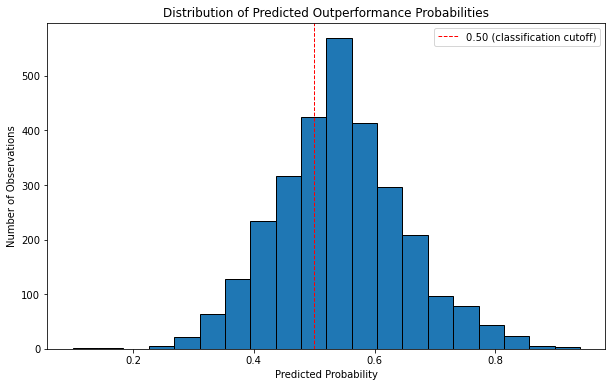

In [29]:
plt.figure(figsize=(10, 6))
plt.hist(test_probabilities, bins=20, edgecolor="black")
plt.axvline(0.5, color="red", linestyle="--", linewidth=1, label="0.50 (classification cutoff)")
plt.title("Distribution of Predicted Outperformance Probabilities")
plt.xlabel("Predicted Probability")
plt.ylabel("Number of Observations")
plt.legend()
plt.show()

The predicted probabilities range from approximately **0.10** to **0.94**, but most observations are concentrated near the center of the distribution, particularly around the **0.50** classification threshold. Relatively few stocks receive probabilities close to **0** or **1**, indicating that the Random Forest rarely produces highly confident predictions in either direction.

This distribution is consistent with the model's weak out-of-sample classification performance. Although the binary classification performance is approximately at chance level and does not exceed the majority-class baseline, the predicted probabilities still provide a continuous measure for ranking stocks. Consequently, ranking stocks by their predicted probabilities preserves more information than applying a fixed **0.50** classification cutoff and forms the basis for the long and short portfolio construction in Part 5.

### 24. Examine Random Forest Feature Importance

Random Forest feature importance measures the relative contribution of each predictor to the model by summarizing how much each variable reduces impurity across all decision trees in the forest. Variables with higher importance scores contribute more to the model's predictions.

Feature importance does not imply a causal relationship, and highly correlated predictors may share or distribute importance between themselves. Consequently, the results are interpreted as an indication of which variables the fitted Random Forest relied on most heavily rather than as evidence that a variable independently causes stock outperformance.

                    Feature  Importance
11         Return on assets    0.025419
31   200-day moving average    0.025434
38              Short ratio    0.025740
15     Qtrly revenue growth    0.025777
21               Total cash    0.025848
8   Enterprise value/ebitda    0.025996
26     Book value per share    0.026043
36   % held by institutions    0.026111
23               Total debt    0.027250
29                     Beta    0.027458
1          Enterprise value    0.027526
22     Total cash per share    0.027690
13                  Revenue    0.027998
0                Market cap    0.028165
16             Gross profit    0.028822


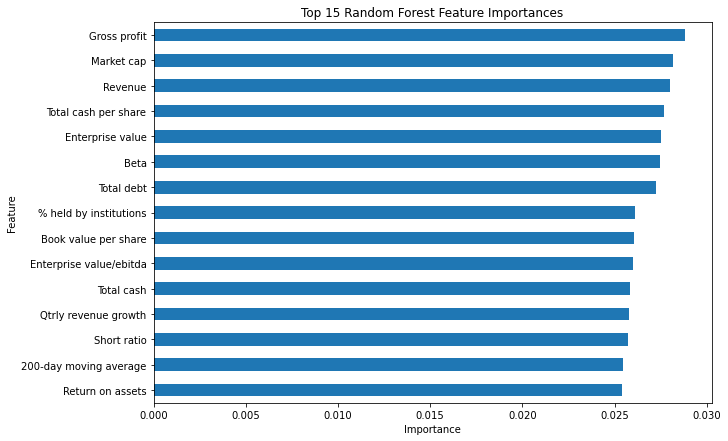

In [30]:
# create a dataframe containing each feature and its
# corresponding importance score. sort the results from
# the most important feature to the least important.

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": random_forest.feature_importances_}).sort_values("Importance", ascending=False)

print(feature_importance.head(15).sort_values("Importance"))

feature_importance.head(15).sort_values("Importance").plot(
    kind="barh",
    x="Feature",
    y="Importance",
    figsize=(10, 7),
    legend=False)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

The most influential predictors include measures of **company size, revenue, cash generation, debt, profitability, market risk,** and **short interest**. However, the importance scores are relatively similar across the leading variables, indicating that the Random Forest draws predictive information from a broad combination of financial characteristics rather than relying on a single dominant predictor.

Because several of these variables are strongly correlated, their individual importance scores should be interpreted with caution. Correlated predictors often share predictive information, causing their importance to be distributed across multiple variables. Consequently, feature importance describes how this particular fitted Random Forest used the available predictors; it does not imply that the highest-ranked variables independently cause future stock outperformance.

## Part 4 Conclusion

The baseline Random Forest fits the training data extremely well but performs poorly on the later testing period, achieving lower accuracy than the majority-class benchmark. The large gap between the training and testing performance provides strong evidence of overfitting and limited out-of-sample classification ability.

Although the model is not an effective binary classifier, it still generates predicted probabilities that provide a continuous measure of confidence for each stock. Rather than relying solely on the binary class labels, the following section investigates whether these probabilities contain enough relative information to rank stocks within each quarter and construct a systematic long and short portfolio.

# Part 5: Quarterly Stock Ranking and Portfolio Construction

The binary class predictions divide stocks into only two categories: outperformers and non-outperformers. For portfolio construction, however, the predicted probabilities are more informative because they provide a continuous measure of the Random Forest's confidence that each stock will outperform the S&P 500.

Stocks are ranked separately within each testing quarter according to their predicted outperformance probabilities. The highest-ranked **10%** of stocks are assigned to the long portfolio, while the lowest-ranked **10%** are assigned to the short portfolio. Using equal-sized long and short portfolios creates a balanced investment strategy and allows the model's relative ranking ability to be evaluated directly.

### 25. Retain One Observation per Stock in Each Quarter

Some companies appear on multiple dates within the same calendar quarter. Ranking every observation would allow the same stock to occupy multiple positions within a single portfolio, giving it disproportionate influence on the quarterly results. To ensure that each company receives only one portfolio allocation per quarter, only the **most recent** observation for each **(Quarter, Ticker)** combination is retained before the ranking process.

In [31]:
# keep only one observation per stock in each quarter.
# if a stock appears multiple times within the same quarter,
# retain the most recent observation based on the date.

# sort chronologically so the latest date is last
# group observations by quarter and stock
# keep the last (most recent) row from each group
# reset the row numbers after filtering

test_results = (
    test_results.sort_values("Date").groupby(["Quarter", "Ticker"])
    .tail(1)
    .reset_index(drop=True))

The ranking unit has now changed from individual stock-date observations to unique stocks within each calendar quarter. Retaining only the most recent observation for each company ensures that every stock can occupy at most one position in the quarterly portfolio. The latest observation is used because it represents the most recent information available for that company before the portfolio is formed.

### 26. Rank Stocks Within Each Quarter

Within each testing quarter, stocks are sorted from the highest to the lowest predicted outperformance probability. A unique rank is then assigned to every stock, with Rank 1 representing the highest predicted probability of outperformance.

The `method="first"` option resolves tied probabilities according to their sorted row order, ensuring that every stock receives a distinct rank. Assigning unique ranks prevents ties from affecting the portfolio selection process and allows the highest- and lowest-ranked stocks to be identified consistently for the long and short portfolios.

In [32]:
# rank the stocks within each quarter based on their
# predicted probability of outperforming. the highest
# probability stock will appear first in each quarter

test_results = test_results.sort_values(
    ["Quarter", "Outperform_probability"],
    ascending=[True, False]).reset_index(drop=True)

# assign a unique rank to every stock within each quarter.
# rank 1 corresponds to the highest predicted probability.
# method="first" ensures that tied probabilities still
# receive unique ranks based on their order in the data

test_results["Quarterly_rank"] = (
    test_results.groupby("Quarter")["Outperform_probability"]
    .rank(method="first", ascending=False))

# Count the number of unique stocks available in each quarter
test_results["Quarter_size"] = (
    test_results.groupby("Quarter")["Ticker"]
    .transform("count"))

test_results 

,Date,Quarter,Ticker,Stock_p_change,Sp500_p_change,Outperform,Predicted_class,Outperform_probability,Quarterly_rank,Quarter_size
0,2011-03-28,2011Q1,XOM,6.26,10.05,0,1,0.780000,1.0,43
1,2011-02-26,2011Q1,FOSL,56.39,5.65,1,1,0.720000,2.0,43
2,2011-02-23,2011Q1,DLX,7.00,6.47,1,1,0.700000,3.0,43
3,2011-03-10,2011Q1,IGT,-0.91,8.09,0,1,0.670000,4.0,43
4,2011-01-15,2011Q1,PBCT,-0.61,1.73,0,1,0.660000,5.0,43
...,...,...,...,...,...,...,...,...,...,...
1990,2013-04-25,2013Q2,INTU,33.37,19.89,1,0,0.304118,458.0,462
1991,2013-04-25,2013Q2,ROP,5.14,19.89,0,0,0.290000,459.0,462
1992,2013-05-10,2013Q2,PAYX,12.11,17.34,0,0,0.290000,460.0,462
1993,2013-05-09,2013Q2,FAST,1.14,17.72,0,0,0.280000,461.0,462


The ranking restarts at **1** within each testing quarter, allowing stocks to be evaluated relative to the other companies available during the same period. Rank **1** corresponds to the highest predicted probability of outperforming the S&P 500, while the largest rank corresponds to the lowest predicted probability. These rankings provide the basis for selecting the top and bottom **10%** of stocks for the long and short portfolios, respectively.

### 27. Assign the Long and Short Portfolios

The highest-ranked and lowest-ranked **10%** of stocks within each quarter are selected for the long and short portfolios. A single portfolio size is calculated for each quarter and applied symmetrically to both sides, ensuring that the long and short portfolios contain the same number of stocks.

Because 10% of the quarterly stock count is not always a whole number, the calculated portfolio size is truncated to an integer. The highest-ranked stocks up to this portfolio size are assigned to the **long** portfolio, while the same number of lowest-ranked stocks are assigned to the **short** portfolio. All remaining stocks are assigned no position.

In [33]:
# select the top and bottom 10% of stocks within each
# quarter to construct the long-short portfolio.
DECILE = 0.10

# calculate how many stocks should be included on each
# side of the portfolio. astype(int) rounds down to the
# nearest whole number since a portfolio cannot contain
# a fraction of a stock.
test_results["Portfolio_size"] = (
    test_results["Quarter_size"] * DECILE).astype(int)

# initialize every stock with no portfolio position.
# positions will be updated in the next two steps.
test_results["Position"] = "None"

# assign the highest-ranked stocks in each quarter to the
# long portfolio. these are the stocks with the largest
# predicted probability of outperforming

test_results.loc[
    test_results["Quarterly_rank"] <= test_results["Portfolio_size"],
    "Position"] = "Long"

# assign the lowest-ranked stocks in each quarter to the
# short portfolio. these are the stocks with the smallest
# predicted probability of outperforming.

test_results.loc[
    test_results["Quarterly_rank"] > test_results["Quarter_size"] - test_results["Portfolio_size"],
    "Position"] = "Short"

test_results

,Date,Quarter,Ticker,Stock_p_change,Sp500_p_change,Outperform,Predicted_class,Outperform_probability,Quarterly_rank,Quarter_size,Portfolio_size,Position
0,2011-03-28,2011Q1,XOM,6.26,10.05,0,1,0.780000,1.0,43,4,Long
1,2011-02-26,2011Q1,FOSL,56.39,5.65,1,1,0.720000,2.0,43,4,Long
2,2011-02-23,2011Q1,DLX,7.00,6.47,1,1,0.700000,3.0,43,4,Long
3,2011-03-10,2011Q1,IGT,-0.91,8.09,0,1,0.670000,4.0,43,4,Long
4,2011-01-15,2011Q1,PBCT,-0.61,1.73,0,1,0.660000,5.0,43,4,None
...,...,...,...,...,...,...,...,...,...,...,...,...
1990,2013-04-25,2013Q2,INTU,33.37,19.89,1,0,0.304118,458.0,462,46,Short
1991,2013-04-25,2013Q2,ROP,5.14,19.89,0,0,0.290000,459.0,462,46,Short
1992,2013-05-10,2013Q2,PAYX,12.11,17.34,0,0,0.290000,460.0,462,46,Short
1993,2013-05-09,2013Q2,FAST,1.14,17.72,0,0,0.280000,461.0,462,46,Short


A percentage-based selection rule is used because the number of available stocks varies substantially across testing quarters. Selecting a fixed number of stocks would cause some quarters to be overrepresented and others to be underrepresented. By selecting the highest- and lowest-ranked **10%** of stocks in each quarter, the portfolio construction methodology remains consistent throughout the testing period despite changes in the size of the available stock universe.

### 28. Verify the Portfolio Construction

The final validation checks confirm that the portfolio construction procedure has been implemented correctly. Specifically, they verify that each quarter contains equal numbers of long and short positions and that every stock appears only once within a given quarter. These checks ensure that the portfolio construction rules have been applied consistently before evaluating the portfolio's investment performance.

In [34]:
# verify that each quarter contains the expected number of
# long and short positions after the portfolio assignment.

# count how many stocks were assigned to each position
# (long, short, or none) within every quarter

position_counts = test_results.groupby(
    ["Quarter", "Position"]).size().unstack(fill_value=0)
print(position_counts)


# verify that each stock appears only once within each
# quarter. duplicate stock-quarter combinations would
# indicate a problem with the earlier filtering step
print("\nDuplicate stock-quarter combinations:",
    test_results.duplicated(subset=["Quarter", "Ticker"]).sum())

# double-check that no stock appears more than once in the
# same quarter. the maximum should be 1 if the data was
# processed correctly
print("\nMaximum observations for any stock within a quarter:",
    test_results.groupby(["Quarter", "Ticker"]).size().max())

# keep only the stocks selected for the long and short
# portfolios. stocks assigned to "None" are excluded from
# the investment strategy.
selected_positions = test_results[
    test_results["Position"].isin(["Long", "Short"])]

selected_positions.head(20)

Position  Long  None  Short
Quarter                    
2011Q1       4    35      4
2011Q2      11    97     11
2011Q3      25   203     25
2011Q4      27   216     27
2012Q1      22   184     22
2012Q2      14   118     14
2012Q3      16   134     16
2012Q4      16   132     16
2013Q1      14   116     14
2013Q2      46   370     46

Duplicate stock-quarter combinations: 0

Maximum observations for any stock within a quarter: 1


,Date,Quarter,Ticker,Stock_p_change,Sp500_p_change,Outperform,Predicted_class,Outperform_probability,Quarterly_rank,Quarter_size,Portfolio_size,Position
0,2011-03-28,2011Q1,XOM,6.26,10.05,0,1,0.78,1.0,43,4,Long
1,2011-02-26,2011Q1,FOSL,56.39,5.65,1,1,0.72,2.0,43,4,Long
2,2011-02-23,2011Q1,DLX,7.00,6.47,1,1,0.70,3.0,43,4,Long
3,2011-03-10,2011Q1,IGT,-0.91,8.09,0,1,0.67,4.0,43,4,Long
39,2011-03-12,2011Q1,RL,39.46,7.35,1,0,0.41,40.0,43,4,Short
40,2011-02-25,2011Q1,CPB,3.93,5.65,0,0,0.40,41.0,43,4,Short
41,2011-01-19,2011Q1,CTXS,2.35,4.65,0,0,0.39,42.0,43,4,Short
42,2011-03-03,2011Q1,DO,-7.63,5.04,0,0,0.32,43.0,43,4,Short
43,2011-06-24,2011Q2,XOM,9.63,7.48,1,1,0.81,1.0,119,11,Long
44,2011-04-01,2011Q2,PKI,6.13,7.98,0,1,0.78,2.0,119,11,Long


The validation confirms that the portfolio construction procedure has been implemented correctly. Each testing quarter contains an equal number of long and short positions, with the portfolio size adjusting automatically according to the number of stocks available in that quarter. For example, the smallest quarter contributes **4** long and **4** short positions, while the largest quarter contributes **46** positions to each side of the portfolio.

The duplicate checks further confirm that every stock appears only once within each calendar quarter, ensuring that no company occupies multiple positions in the same portfolio. Although the selected portfolios still contain individual prediction errors, this is expected because the Random Forest is not a perfect classifier. The following section evaluates whether the **long portfolio nevertheless earns higher average returns than the short portfolio across the testing quarters**, which is the primary objective of the portfolio strategy.

## Part 5 Conclusion

The Random Forest's predicted probabilities have now been transformed into a systematic portfolio construction methodology. Specifically:

- One latest observation is retained for each stock within every calendar quarter.
- Stocks are ranked according to their predicted probability of outperforming the S&P 500.
- The highest-ranked **10%** of stocks form the long portfolio.
- The lowest-ranked **10%** of stocks form the short portfolio.
- Equal numbers of long and short positions are maintained in every quarter.
- Each stock appears at most once within a given quarter, ensuring unique portfolio positions.

The next stage evaluates the realized performance of these portfolios by calculating the average long return, average short return, and long-short return spread for each testing quarter. Because the forward-return windows overlap across quarters, the results are interpreted as repeated **cross-sectional portfolio evaluations** rather than as a continuously compounded investment strategy.

# Part 6: Portfolio Return Evaluation

The previous section used the Random Forest's predicted probabilities to rank stocks within each testing quarter and assign the highest-ranked stocks to the long portfolio and the lowest-ranked stocks to the short portfolio.

This section evaluates how those portfolios performed using their realized forward returns. For each testing quarter, the average forward return of the long portfolio and the average forward return of the short portfolio are calculated. The **long-short return** is then defined as the difference between these two averages.

The returns are **not compounded** into a cumulative equity curve because the forward-return windows overlap across testing quarters. Consequently, each quarter is treated as an independent **cross-sectional portfolio evaluation** rather than as one period in a continuously invested strategy.

### 29. Calculate the Average Long and Short Portfolio Returns

The first step is to calculate the mean realized forward return of the stocks assigned to each side of the portfolio. Grouping the selected positions by **Quarter** and **Position** produces one average long return and one average short-portfolio return for each testing quarter.

In [35]:
# calculate the average stock return for the long and short
# portfolios within each quarter. this gives the quarterly
# return of each side of the investment strategy.

portfolio_returns = (
    selected_positions
    .groupby(["Quarter", "Position"])["Stock_p_change"]
    .mean()
    .unstack())

portfolio_returns

Position,Long,Short
Quarter,,
2011Q1,17.185000,9.527500
2011Q2,-2.902727,0.715455
2011Q3,31.829600,18.503200
2011Q4,19.178148,21.416667
2012Q1,21.990455,12.464545
2012Q2,18.902143,20.294286
2012Q3,77.755625,39.665625
2012Q4,37.963750,38.990000
2013Q1,43.122857,17.337857


The table reports the average realized forward return of the long and short portfolios for each testing quarter. The **Long** column represents the average return earned by the highest-ranked stocks, while the **Short** column reports the average realized return of the stocks assigned to the short portfolio before accounting for the mechanics of short selling.

Because the **Short** column reports the underlying stock returns rather than investor profits, lower values indicate better short selections. A negative return would generate a gain for a short seller, whereas a positive return represents a loss on the short side of the portfolio. The next step combines these two columns into a single long-short return spread, allowing the model's overall stock-ranking ability to be evaluated.

### 30. Calculate the Long-Short Return Spread

The long-short return is defined as the difference between the average return of the long portfolio and the average return of the short portfolio:

$$\text{Long-Short Return} = \text{Average Long Return} - \text{Average Short Return}$$


This measure is interpreted as a **return spread** between the two ranked groups rather than as the realized return of a specific dollar-neutral investment strategy. A positive spread indicates that the model's highest-ranked stocks earned a greater average forward return than its lowest-ranked stocks during that testing quarter, while a negative spread indicates the opposite.

In [36]:
# Calculate the return spread between the long and short portfolios

portfolio_returns["Long_short_return"] = (
    portfolio_returns["Long"] - portfolio_returns["Short"])

portfolio_returns


Position,Long,Short,Long_short_return
Quarter,,,
2011Q1,17.185000,9.527500,7.657500
2011Q2,-2.902727,0.715455,-3.618182
2011Q3,31.829600,18.503200,13.326400
2011Q4,19.178148,21.416667,-2.238519
2012Q1,21.990455,12.464545,9.525909
2012Q2,18.902143,20.294286,-1.392143
2012Q3,77.755625,39.665625,38.090000
2012Q4,37.963750,38.990000,-1.026250
2013Q1,43.122857,17.337857,25.785000


The long-short return spread is positive in **six** of the **ten** testing quarters and negative in the remaining **four**. The strongest positive spread occurs in **2012Q3**, while the weakest occurs in **2011Q2**.

These results indicate that the Random Forest's ranking was not consistently successful in every quarter. Nevertheless, the long portfolio outperformed the short portfolio more often than not, suggesting that the predicted probabilities contain some useful relative ranking information despite the model's weak binary classification performance.

### 31. Add the S&P 500 Benchmark

The average forward return of the S&P 500 is calculated separately for each testing quarter using the same **unique stock population** created during **Part 5, Step 25**. This ensures that each company contributes only once to the quarterly benchmark calculation and prevents companies that originally appeared multiple times within a quarter from receiving disproportionate weight.

The benchmark provides market context for interpreting the portfolio returns. However, it should not be compared directly with the long-short return spread because the two measures represent different investment concepts. The S&P 500 benchmark reflects the return of a long-only market investment, whereas the long-short spread measures the relative performance of the model's highest- and lowest-ranked stocks.

In [37]:
# calculate the average S&P 500 forward return for each
# testing quarter using the unique stock population created
# earlier, where each stock contributes only once

sp500_returns = (
    test_results.groupby("Quarter")["Sp500_p_change"].mean()
)

# Add the benchmark to the portfolio-return table
portfolio_returns["Sp500_return"] = sp500_returns

portfolio_returns

Position,Long,Short,Long_short_return,Sp500_return
Quarter,,,,
2011Q1,17.185000,9.527500,7.657500,6.080930
2011Q2,-2.902727,0.715455,-3.618182,4.545126
2011Q3,31.829600,18.503200,13.326400,22.649605
2011Q4,19.178148,21.416667,-2.238519,15.806889
2012Q1,21.990455,12.464545,9.525909,14.795044
2012Q2,18.902143,20.294286,-1.392143,22.565411
2012Q3,77.755625,39.665625,38.090000,22.276928
2012Q4,37.963750,38.990000,-1.026250,27.559573
2013Q1,43.122857,17.337857,25.785000,21.420972


The S&P 500 benchmark records positive average forward returns in every testing quarter, indicating that the evaluation period was generally characterized by favorable market conditions. Consequently, positive returns from the long portfolio alone do not necessarily demonstrate successful stock selection.

The more informative measure is the **long-short return spread**, which evaluates whether the Random Forest consistently ranked stocks that subsequently performed better than those assigned to the short portfolio. Comparing the long and short groups therefore provides a clearer assessment of the model's stock-selection ability than comparison with the market benchmark alone.

### 32. Review Descriptive Statistics

Descriptive statistics summarize the distribution of the quarterly **long**, **short**, **long-short**, and **S&P 500 benchmark** returns across the ten testing quarters. The mean measures the average return across quarters, the standard deviation measures the variability of those quarterly returns, and the minimum and maximum identify the weakest and strongest observed outcomes.

In [38]:
# Summarize the distribution of the portfolio and benchmark returns

portfolio_returns.describe()

Position,Long,Short,Long_short_return,Sp500_return
count,10.000000,10.000000,10.000000,10.000000
mean,29.013246,19.586687,9.426559,17.567193
std,21.304715,12.040264,13.505962,7.454673
min,-2.902727,0.715455,-3.618182,4.545126
25%,18.971144,13.586344,-1.300670,15.048005
50%,23.549032,17.920529,7.906685,19.696211
75%,36.430213,21.136071,12.376277,22.493290
max,77.755625,39.665625,38.090000,27.559573


The long portfolio earns an average forward return of approximately **29.01%**, compared with approximately **19.59%** for the stocks assigned to the short portfolio. This difference produces an average long-short return spread of approximately **9.43%**, indicating that, on average, the model ranked higher-performing stocks above lower-performing stocks during the testing period.

The long-short return spread has a standard deviation of approximately **13.51%**, indicating considerable variation in the model's ranking performance across testing quarters. Some quarters exhibit strong positive spreads, whereas others produce negative spreads. Because the evaluation is based on only **ten** testing quarters, these summary statistics should be interpreted cautiously, as a small number of unusually strong or weak quarters can have a meaningful influence on the reported averages.

### 33. Visualize Portfolio Performance by Testing Quarter

A bar chart is used instead of a cumulative return plot because each testing quarter is treated as an independent cross-sectional portfolio evaluation. The figure compares the average forward returns of the long portfolio, short portfolio, long-short return spread, and S&P 500 benchmark, making it easier to identify quarters in which the ranking performed well or poorly relative to the market.

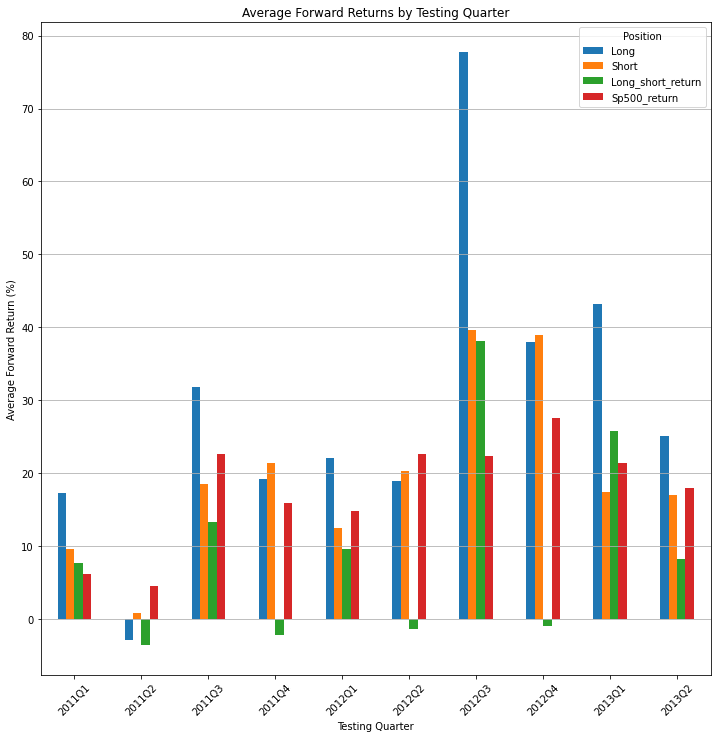

In [39]:
# Compare the long, short, long-short, and benchmark returns
# across the portfolio quarters

portfolio_returns[
    ["Long", "Short", "Long_short_return", "Sp500_return"]].plot(
    kind="bar",
    figsize=(12, 12))

plt.title("Average Forward Returns by Testing Quarter")
plt.xlabel("Testing Quarter")
plt.ylabel("Average Forward Return (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

The figure confirms that the long portfolio generally earns a higher average forward return than the short portfolio, although this relationship does not hold in every testing quarter. The largest positive long-short return spreads occur in **2012Q3** and **2013Q1**, while several quarters produce negative spreads, indicating that the model's ranking was not consistently successful throughout the testing period.

The S&P 500 benchmark remains positive in every quarter, reflecting the generally favorable market environment during the sample period. Despite these positive market conditions, the long-short return spread varies considerably across quarters, reinforcing the importance of evaluating both average performance and risk rather than relying solely on the mean return.

### 34. Compare the Long-Short Return Spread with the S&P 500

The final chart isolates the long-short return spread and the S&P 500 benchmark. The two series answer different questions: the benchmark describes the overall market environment during each testing quarter, whereas the long-short spread evaluates whether the Random Forest successfully separated stronger-performing stocks from weaker-performing stocks.

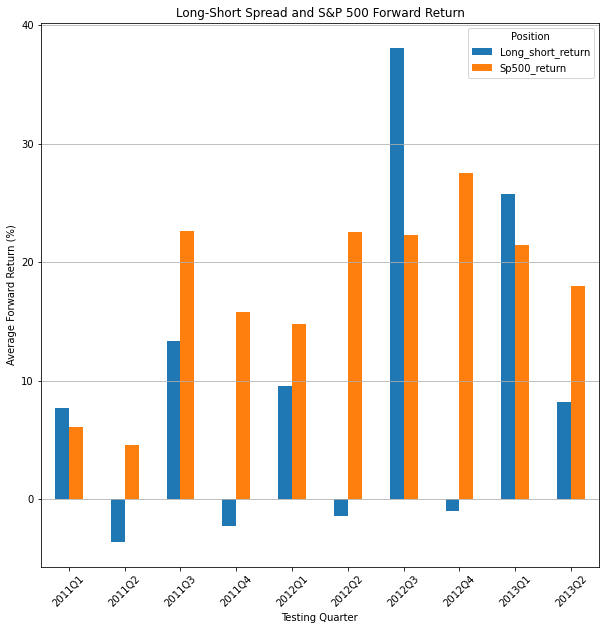

In [40]:
# Compare the long-short return spread with the market benchmark

portfolio_returns[
    ["Long_short_return", "Sp500_return"]].plot(
    kind="bar",
    figsize=(10, 10))

plt.title("Long-Short Spread and S&P 500 Forward Return")
plt.xlabel("Testing Quarter")
plt.ylabel("Average Forward Return (%)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

The long-short return spread does not consistently exceed the S&P 500 benchmark, but this is not the primary objective because the two measures represent fundamentally different investment concepts. The S&P 500 reflects the return of a long-only market investment, whereas the long-short spread measures the model's stock-selection ability.

The benchmark remains positive throughout the testing period, indicating a generally favorable market environment. Nevertheless, the long-short spread is positive in most testing quarters and positive on average, suggesting that the predicted probabilities contain useful relative ranking information despite the Random Forest's weak binary classification performance.

## Part 6 Conclusion

The portfolio construction methodology has now been translated into realized forward returns. Across the **ten testing quarters**, the long portfolio earns a higher average return than the short portfolio, producing an average long-short return spread of approximately **9.43%**.

The quarterly returns are not compounded because the forward-return windows overlap across testing quarters. Instead, each quarter is treated as an independent cross-sectional portfolio evaluation. The following section therefore analyzes the distribution of these ten long-short return observations using the **Sharpe Ratio**, **Sortino Ratio**, **Historical Value at Risk (VaR)**, and **Historical Conditional Value at Risk (CVaR)**.

# Part 7: Risk Evaluation

Part 6 demonstrated that the long-short portfolio earns a positive average return spread. However, average return alone does not indicate whether the strategy is stable or whether that return is achieved with substantial risk. This section therefore evaluates the distribution of the ten quarterly long-short return observations.

The analysis considers total variability, downside variability, and historical tail risk. The reported **Sharpe Ratio** and **Sortino Ratio** are calculated using the quarterly long-short return observations and are **not annualized**, because the strategy is evaluated as repeated cross-sectional portfolio returns rather than as a continuously invested time series.

### 35. Extract the Quarterly Long-Short Return Series

The quarterly long-short return series is extracted because it represents the primary output of the portfolio strategy and serves as the input for all subsequent risk calculations. A one-column table is also displayed to make the quarterly return observations easier to inspect.

In [41]:
# Extract the quarterly long-short returns for the risk calculations

strategy_returns = portfolio_returns["Long_short_return"]

# Display the same values as a one-column table
strategy_returns_display = portfolio_returns[["Long_short_return"]]

strategy_returns_display

Position,Long_short_return
Quarter,
2011Q1,7.657500
2011Q2,-3.618182
2011Q3,13.326400
2011Q4,-2.238519
2012Q1,9.525909
2012Q2,-1.392143
2012Q3,38.090000
2012Q4,-1.026250
2013Q1,25.785000


The strategy produces **six** positive and **four** negative long-short return observations. The largest positive spread is approximately **38.09%**, while the largest negative spread is approximately **−3.62%**. Overall, the distribution is characterized by several relatively large positive return spreads and comparatively smaller negative spreads, suggesting that successful quarters contribute more heavily to the strategy's average return than unsuccessful quarters.

### 36. Calculate the Quarterly Sharpe Ratio

The Sharpe Ratio measures the average return earned per unit of total return variability:

$$\text{Sharpe Ratio} = \frac{\text{Average Return}}{\text{Standard Deviation}}$$

A risk-free rate is not subtracted, and the ratio is not annualized. This is a deliberate methodological choice because the available observations represent repeated cross-sectional long-short return spreads rather than a conventional sequence of non-overlapping quarterly investment returns.

In [42]:
# Calculate the average return and standard deviation

average_return = strategy_returns.mean()
strategy_returns_std = strategy_returns.std()

# Calculate the quarterly, non-annualizaed Sharpe Ratio

sharpe_ratio = average_return / strategy_returns_std

print("Average Return:", average_return, "\n")
print("Standard Deviation:", strategy_returns_std, "\n")
print("Quarterly Sharpe Ratio:", sharpe_ratio)

Average Return: 9.42655854622833 

Standard Deviation: 13.50596212358234 

Quarterly Sharpe Ratio: 0.6979553518641156


The average long-short return spread is approximately **9.43%**, while its standard deviation is approximately **13.51%**, producing a quarterly, non-annualized Sharpe Ratio of approximately **0.70**.

The positive Sharpe Ratio indicates that the strategy generates a positive average return spread relative to its overall variability. However, because the ratio remains below **1**, the strategy earns a positive return spread but with a relatively modest reward per unit of total risk. Furthermore, the return spread varies considerably across testing quarters. This value should not be compared directly with annualized Sharpe Ratios reported for continuously invested portfolios because it is calculated from repeated cross-sectional portfolio evaluations rather than a continuous investment time series.

### 37. Calculate the Quarterly Sortino Ratio

The Sortino Ratio measures the average return earned per unit of downside variability. Unlike the Sharpe Ratio, it focuses only on unfavorable outcomes and does not penalize positive return variation.

A target return of **0%** is used to calculate downside deviation. Negative long-short returns are measured relative to this target, while positive returns contribute zero downside deviation. This focuses the risk measure on quarters in which the strategy produced a negative return spread.

In [43]:
# Retain downside returns relative to a target return of 0

downside_returns = np.minimum(strategy_returns, 0)
print(downside_returns)

# Calculate downside deviation and the quarterly Sortino Ratio

downside_deviation = np.sqrt(
    np.mean(downside_returns ** 2))

# calculate the quarterly, non-annualized Sortino Ratio
sortino_ratio = average_return / downside_deviation

print("\nDownside Deviation:", downside_deviation)
print("\nQuarterly Sortino Ratio:", sortino_ratio)

Quarter
2011Q1    0.000000
2011Q2   -3.618182
2011Q3    0.000000
2011Q4   -2.238519
2012Q1    0.000000
2012Q2   -1.392143
2012Q3    0.000000
2012Q4   -1.026250
2013Q1    0.000000
2013Q2    0.000000
Freq: Q-DEC, Name: Long_short_return, dtype: float64

Downside Deviation: 1.4523586204641648

Quarterly Sortino Ratio: 6.490517158369371


Four of the ten testing quarters produce negative long-short return spreads. Using a target return of **0%**, the downside deviation is approximately **1.45%**, resulting in a quarterly, non-annualized Sortino Ratio of approximately **6.49**.

The Sortino Ratio is substantially larger than the Sharpe Ratio because the strategy's negative return spreads are relatively small compared with its positive average return. Unlike the Sharpe Ratio, positive volatility does not increase the denominator, so the several large positive spreads do not penalize the Sortino Ratio.

However, the result should still be interpreted cautiously. The risk estimate is based on only **ten testing-quarter observations**, of which only **four** contain negative spreads. Consequently, the Sortino Ratio may be sensitive to the small out-of-sample evaluation period and should be viewed as a descriptive measure rather than strong evidence of consistently low downside risk.

### 38. Calculate Historical Value at Risk and Historical Conditional Value at Risk

Historical **Value at Risk (VaR)** estimates downside risk directly from the observed return distribution without assuming that returns follow a normal distribution. The **95% Historical VaR** identifies the return threshold below which the worst **5%** of observed outcomes fall.

Historical **Conditional Value at Risk (CVaR)**, also called **Expected Shortfall**, measures the average return of all observations at or below the VaR threshold. Whereas VaR identifies a cutoff point, CVaR measures the average severity of losses beyond that cutoff.

In [44]:
# Calculate the 95% Historical Value at Risk

historical_var_95 = strategy_returns.quantile(0.05)
print("Historical VaR (95%):", historical_var_95)

# Calculate the 95% Historical Conditional Value at Risk

historical_cvar_95 = (
    strategy_returns[strategy_returns <= historical_var_95].mean())

print("\nHistorical CVaR (95%):", historical_cvar_95)

Historical VaR (95%): -2.9973333333333345

Historical CVaR (95%): -3.618181818181818


The **95% Historical VaR** is approximately **−3.00%**, representing the estimated 5th percentile of the observed long-short return distribution.

The **95% Historical CVaR** is approximately **−3.62%**, corresponding to the average return of observations at or below the VaR threshold. In this dataset, that value is equal to the worst observed testing quarter because only one return falls below the estimated VaR.

Because the risk measures are calculated from only **ten** testing-quarter observations, the lower tail of the distribution contains very limited information. Consequently, the Historical VaR and CVaR should be interpreted as descriptive statistics for this sample rather than as precise estimates of future extreme losses.

### 39. Summarize the Risk Metrics

The final step combines the performance and risk measures into a single summary table. Presenting the average return, return variability, risk-adjusted performance, and historical downside-risk, etc measures together makes it easier to evaluate the portfolio strategy as a whole and compare the different metrics in one place.

In [45]:
# Summarize the risk evaluation results

risk_summary = pd.DataFrame({

    "Metric": [
        "Average Return",
        "Standard Deviation",
        "Quarterly Sharpe Ratio",
        "Quarterly Sortino Ratio",
        "Historical VaR (95%)",
        "Historical CVaR (95%)"
    ],

    "Value": [
        average_return,
        strategy_returns_std,
        sharpe_ratio,
        sortino_ratio,
        historical_var_95,
        historical_cvar_95
    ]})

risk_summary

,Metric,Value
0,Average Return,9.426559
1,Standard Deviation,13.505962
2,Quarterly Sharpe Ratio,0.697955
3,Quarterly Sortino Ratio,6.490517
4,Historical VaR (95%),-2.997333
5,Historical CVaR (95%),-3.618182


The risk summary presents a balanced assessment of the portfolio strategy. The model's ranking produces a positive average long-short return spread and a positive quarterly Sharpe Ratio, suggesting that the Random Forest's predicted probabilities contain some useful relative stock-selection information. At the same time, the return spread varies substantially across testing quarters, while the relatively large quarterly Sortino Ratio reflects the limited observed downside variation.

The Sortino Ratio and historical tail-risk measures should be interpreted cautiously because the evaluation contains only **ten testing-quarter observations**, with only **four** quarters contributing non-zero downside deviations. These limitations do not make the calculations incorrect, but they reduce the confidence with which the reported risk metrics can be generalized beyond the observed testing period. The measures should therefore be interpreted primarily as descriptive statistics for this sample.

## Part 7 Conclusion

The long-short portfolio produces a positive average forward-return spread and a quarterly Sharpe Ratio of approximately **0.70**, indicating positive but moderate risk-adjusted performance. The substantially larger quarterly Sortino Ratio of approximately **6.49** reflects the relatively small observed downside variation. However, it should be interpreted cautiously because the analysis contains only **ten testing-quarter observations**, with only **four** quarters contributing non-zero downside deviations.

Historical **Value at Risk (VaR)** and **Conditional Value at Risk (CVaR)** provide an empirical view of the lower tail of the observed return distribution. However, because these measures are calculated from only **ten testing-quarter observations**, they should be interpreted as descriptive statistics for this sample rather than as precise estimates of future downside risk.

Overall, the risk analysis suggests that the Random Forest's predicted probabilities contain some useful relative stock-selection information. However, the evidence remains limited by the small out-of-sample testing period and should therefore be interpreted cautiously.

The final section synthesizes the model, portfolio, and risk findings, discusses the project's methodological limitations, relates the implementation to the course material, and identifies realistic directions for future improvement.

# Part 8: Discussion, Limitations, and Future Improvements

This section synthesizes the findings from Parts 4 through 7, discusses the project's methodological limitations, connects the implementation to course concepts, and outlines realistic directions for future work. No new analysis is introduced here.

### 40. Summary of the Project

This project investigated whether a Random Forest classifier trained on company fundamental, valuation, market, and trading-related characteristics could identify stocks that would subsequently outperform the S&P 500. Rather than relying solely on binary classifications, the predicted probabilities were used to rank stocks within each testing quarter and construct equal-sized long and short portfolios.

The analysis followed a chronological machine-learning workflow because financial data are time-sensitive, meaning that the chronological order of the observations is essential throughout the modeling process. The dataset was cleaned, organized into calendar quarters, divided into chronological training and testing periods, preprocessed using training-set statistics only to avoid data leakege from occuring, and used to train a baseline Random Forest classifier. The predicted probabilities were then converted into quarterly portfolio rankings, allowing the model to be evaluated from both a classification and an investment perspective.

### 41. Main Findings

The Random Forest achieved nearly perfect training accuracy of approximately **99.6%** but only **49.1%** testing accuracy, which was slightly below the **50.1%** majority-class baseline. This large difference between training and testing performance indicates substantial overfitting and limited out-of-sample classification ability. It also informs us as data scientists that the model still needs substantial hyperparameter tuning in order to reduce overfitting and improve its performance on unseen data. 

The distribution of predicted probabilities also showed that many observations were concentrated near the **0.50** classification threshold, while relatively few stocks received probabilities close to either extreme. This indicates that the model generally produced limited separation between the two classes when evaluated as a binary classifier.

Despite the weak classification results, the predicted probabilities provided some useful relative information when stocks were ranked within each testing quarter. The long portfolio, consisting of the highest-ranked stocks, earned an average forward return of approximately **29%**, compared with approximately **19.6%** for the stocks assigned to the short portfolio. The resulting average long-short return spread was approximately **9.43%** and was positive in **6 of the 10** testing quarters.

These results suggest that the probability ranking provided some separation between the highest and lowest ranked stocks, although the ranking was not consistently successful in every testing quarter. The short side also remained relatively weak because the stocks assigned to the short portfolio still earned positive forward returns on average.

The average S&P 500 forward-return benchmark across the same testing observations was approximately **17.6%**, reflecting a generally favorable market environment during the testing period. This reinforces the importance of evaluating the long-short spread rather than interpreting positive long-portfolio returns alone as evidence of successful stock selection.

The risk analysis produced a quarterly, non-annualized Sharpe Ratio of approximately **0.70**, indicating positive but moderate risk-adjusted performance. The quarterly Sortino Ratio, calculated using a **0% target return**, was approximately **6.49**. The larger Sortino Ratio reflects the relatively limited downside variation observed in the sample, as only four testing quarters produced negative long-short spreads.

Historical VaR and CVaR at the **95%** level were approximately **−3.00%** and **−3.62%**, respectively. These values provide a descriptive view of the lower tail of the observed return distribution, but they should not be interpreted as precise forecasts because the evaluation contains only ten testing-quarter observations.

### 42. Limitations

Several limitations should be considered when interpreting these results.

**Sample size.** The out-of-sample evaluation consists of only **10 testing quarters**. As a result, the average portfolio returns and risk metrics are sensitive to a relatively small number of observations. The Sortino Ratio is particularly sensitive because only four quarters contribute non-zero downside deviations, while the Historical CVaR is effectively determined by the single worst observed quarter.

**Overlapping forward-return windows.** The stock and S&P 500 percentage-change variables represent forward returns, and these forward-return windows may overlap across adjacent testing quarters. For this reason, the quarterly results are treated as repeated cross-sectional portfolio evaluations rather than compounded into a cumulative equity curve. This also limits the interpretation of performance measures that assume a conventional, continuously invested portfolio with non-overlapping return periods.

**Different observation dates within a quarter.** Only the most recent observation for each (Quarter, Ticker) combination is retained before the stocks are ranked. Because these observations may come from different dates within the same quarter, the results should be interpreted as a cross-sectional evaluation of stock-ranking ability rather than as a fully synchronized portfolio backtest.

**Predictors.** Although the research question emphasizes company fundamentals, the 41 predictor variables include not only accounting and valuation measures but also market and trading-related variables such as Beta, moving averages, trading volume, and short-interest measures. The model is therefore more precisely described as using a combination of fundamental, valuation, market, and trading-related characteristics.

**Baseline model.** The Random Forest was intentionally implemented as an untuned baseline model. Its nearly perfect training accuracy and weak testing accuracy indicate substantial overfitting, suggesting that model regularization or hyperparameter tuning could be explored in future work.

**Practical investment constraints.** The project evaluates relative stock-ranking ability rather than a directly deployable trading strategy. Transaction costs, taxes, liquidity constraints, short-selling costs, turnover, and practical execution timing are outside the scope of the analysis and would affect realized investment performance.

### 43. Relationship to Course Concepts

This project applies several statistical, machine-learning, and financial concepts developed throughout the course.

The chronological train-test split reflects the importance of preserving time order in financial data and avoiding look-ahead bias. Missing predictor values are imputed using statistics calculated from the training data only, reducing the risk of data leakage from the later testing period.

The Random Forest applies ensemble learning to a binary classification problem, while testing accuracy, precision, recall, the F1 score, and the confusion matrix provide multiple perspectives on out-of-sample model performance. The difference between the model's strong training accuracy and weak testing accuracy also provides a practical example of overfitting.

The project further extends the classification analysis by using predicted probabilities as continuous ranking scores rather than relying only on binary class labels. These probability rankings are then incorporated into a long-short portfolio construction framework, connecting machine-learning predictions with quantitative investment analysis.

Finally, the Sharpe Ratio, Sortino Ratio, Historical VaR, and Historical CVaR provide measures of total variability, downside variability, and tail risk. These measures are adapted to the structure of the available testing observations and are interpreted cautiously because the returns are repeated cross-sectional evaluations rather than a conventional continuous investment time series.

### 44. Future Improvements

Several extensions could strengthen the analysis while preserving the chronological structure of the project.

Future work could apply walk-forward hyperparameter tuning to reduce the overfitting observed in Part 4. Potential Random Forest parameters include maximum tree depth, minimum leaf size, and the number of features considered at each split.

Feature reduction could also be explored using the highly correlated predictor pairs identified in Part 1. Removing or combining redundant variables may improve model interpretability and could potentially reduce overfitting.

The Random Forest could also be compared with alternative classification models, such as logistic regression or gradient-boosting methods. Model comparisons should examine not only overall classification accuracy but also whether the probability rankings produce stronger separation between the highest and lowest ranked stocks.

A longer out-of-sample testing period spanning additional market environments would provide a more reliable assessment of portfolio performance and downside risk. Future work could also incorporate transaction costs, turnover, short-selling costs, and synchronized portfolio formation dates to produce an evaluation that more closely resembles practical investment implementation.

## Final Conclusion

Although the baseline Random Forest did not achieve strong out-of-sample classification accuracy, its predicted probabilities provided some useful relative separation when stocks were ranked within testing quarters. The resulting long-short return spread was positive on average and in **6 of the 10** testing quarters, although performance was inconsistent and the stocks assigned to the short portfolio still earned positive returns on average.

The risk-adjusted results were also cautiously positive, with a quarterly Sharpe Ratio of approximately **0.70**, but the small testing sample limits how confidently any of the performance and risk statistics can be generalized.

Overall, the project does not demonstrate a production-ready investment strategy. Instead, it provides evidence that machine-learning probability estimates can be incorporated into a systematic stock-ranking framework while also highlighting the importance of chronological evaluation, data-leakage prevention, portfolio construction, and careful interpretation of financial risk measures.

The analysis therefore establishes a complete baseline framework that can be extended through model tuning, alternative algorithms, improved portfolio implementation, and a larger out-of-sample evaluation period.